# P1 · Boiling point: one-shot ten-step workflow

This notebook builds, tests and saves a model that predicts a molecule's **normal boiling point (K)** from its **SMILES** string, in one complete pass through the ten-step workflow from [01 · Ten steps in prompts](../../../01_Ten_Steps_in_Prompts.ipynb). Steps 0–3 set the goal and data; Step 4 audits the data and seals a molecule-disjoint test set; Step 5 cleans labels and engineers chemistry features; Steps 6–7 define models and run tracked experiments on training/validation data only; Step 8 analyzes errors chemically; Step 9 makes one bounded improvement and freezes the pipeline; Step 10 opens the test set exactly once and reports what happened.

All generated files are written to `01_boiling_point/outputs/one_shot_p1/`. The source data and other notebooks are never modified.

### Reading and presenting this notebook

Each code block has a descriptive heading followed by a short explanation labeled **Code Summary:**; saved outputs remain visible. In **VS Code**, open the Command Palette (`Ctrl+Shift+P` on Windows/Linux, `Cmd+Shift+P` on macOS) and choose **Notebook: Collapse All Cell Inputs**; use **Expand All Cell Inputs** to read or edit code. In **JupyterLab**, code inputs start hidden via notebook metadata; expand them with the left-hand cell collapser. Hiding code does not change execution.

<h1 style="color:#1D4E89;">Step 0: Conditioning the Coding Assistant</h1>

**Project context.** We want a model that reads only a SMILES string and returns a reported normal boiling point in kelvin, trained on a NIST-derived table of about 3,500 compounds. The assistant acts as an ML engineer and computational chemist for a mixed-experience audience, so every decision is explained in plain language. **Guardrails:** (1) the only model input is SMILES — CAS numbers, the provided MW column and the NIST 3D geometry are never features; (2) splits are *molecule-disjoint* (the same structure never appears in two splits) and are saved once and reused; (3) anything the model learns from data — imputation, scaling, feature filtering, model weights — is fit on the training split only, inside a single scikit-learn `Pipeline`; (4) models and settings are chosen on validation data only; (5) the test set stays sealed until the pipeline is frozen at the end of Step 9 and is then used exactly once in Step 10.

<h1 style="color:#1D4E89;">Step 1: Set Goal</h1>

1. **Intention:** predict the normal boiling point (K) of a molecule from its SMILES string, as accurately as possible for molecules the model has never seen.
2. **Approach:** supervised regression with SMILES-derived chemistry features (RDKit descriptors, fingerprints and a group-contribution estimate) trained on `01_boiling_point/data/CompoundData.parquet`.
3. **Success:** the primary metric is **test MAE in K** (mean absolute error — the average size of a miss, in kelvin); **RMSE** (root-mean-square error, which punishes large misses more) and **R²** (fraction of the boiling-point variance explained) are secondary.
4. **Threshold:** **test MAE ≤ 15 K**, *and* clearly better than (a) a training-median baseline and (b) a cheap linear Ridge reference model (at least 10% lower MAE).

**Why 15 K?** Boiling points in this file span roughly 77–720 K with a standard deviation of about 70 K, so predicting the median would miss by ~55 K on average. Carefully measured boiling points are reproducible to 1–3 K, but compiled literature tables for diverse compounds routinely disagree by 5–10 K (Step 4 shows repeated reports in this very file differ by several kelvin). Classical group-contribution methods such as Joback with the Stein–Brown correction typically average 15–25 K error on diverse organics. A 15 K target therefore asks the model to match or beat the best classical estimate while staying a few times above the label noise floor — ambitious but realistic.

<h1 style="color:#1D4E89;">Step 2: Define Inputs and Outputs</h1>

**Input:** one SMILES string (e.g. `CCO`). **Output:** one predicted normal boiling point in kelvin (e.g. `351 K`).

<h1 style="color:#1D4E89;">Step 3: Collect Data</h1>

The data are pre-collected: `01_boiling_point/data/CompoundData.parquet`, 3,541 rows with columns CAS, MW, BP (K), SMILES and mol3D. The records were derived from the NIST Chemistry WebBook by the workshop acquisition notebook (`00_BP_Get_Data_NISTChemPy_v2.ipynb`). Nothing is downloaded here.

### Set up paths, seeds and package versions

Code Summary: Imports the libraries, finds the repository root, creates the output folders, fixes random seeds and records package versions so the run can be reproduced.

In [1]:
import importlib, json, platform, random, shutil, sys, time, warnings
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rdkit
import sklearn
from IPython.display import display
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RDLogger.DisableLog('rdApp.*')
warnings.filterwarnings('ignore', category=FutureWarning)
NOTEBOOK_START = time.perf_counter()
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

repo = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').is_file() and (p / '01_boiling_point').is_dir()), None)
if repo is None:
    raise FileNotFoundError('Start Jupyter inside the workshop repository.')
MODULE = repo / '01_boiling_point'
DATA_PATH = MODULE / 'data' / 'CompoundData.parquet'
OUT = MODULE / 'outputs' / 'one_shot_p1'
FIG_DIR, EXP_DIR = OUT / 'figures', OUT / 'experiments'
for folder in (OUT, FIG_DIR, EXP_DIR):
    folder.mkdir(parents=True, exist_ok=True)
FEATURE_MODULE = str(OUT / 'bp_one_shot_features.py')

def rel(path):
    return Path(path).relative_to(repo).as_posix()

def save_fig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print('Saved figure:', rel(path))

def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return {'MAE_K': mean_absolute_error(y_true, y_pred),
            'RMSE_K': float(np.sqrt(mean_squared_error(y_true, y_pred))),
            'R2': r2_score(y_true, y_pred), 'n': int(len(y_true))}

plt.rcParams.update({'figure.dpi': 100, 'font.size': 11, 'axes.titlesize': 12,
                     'axes.labelsize': 11, 'legend.fontsize': 9})
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'rdkit': rdkit.__version__,
            'matplotlib': matplotlib.__version__, 'joblib': joblib.__version__, 'seed': SEED}
(OUT / 'environment_versions.json').write_text(json.dumps(versions, indent=2))
print(f'Outputs -> {rel(OUT)}')
print(json.dumps(versions, indent=2))

Outputs -> 01_boiling_point/outputs/one_shot_p1
{
  "python": "3.11.18",
  "numpy": "2.0.0",
  "pandas": "2.2.3",
  "scikit-learn": "1.6.1",
  "rdkit": "2024.03.6",
  "matplotlib": "3.10.0",
  "joblib": "1.6.0",
  "seed": 42
}


<h2 style="color:#1D4E89;">Step 4: Examine Data</h2>

<h3 style="color:#B05E27;">Decision and rationale</h3>

**What:** check the schema, then run *deterministic* eligibility checks that do not look at the boiling point — missing or unparsable SMILES, non-finite targets, multi-component (salt/mixture) or net-charged species — and assign every structure a canonical identity. Then reserve a reproducible **80/10/10 train/validation/test split (seed 42)** and save it. Only *after* the split do we look at boiling-point distributions, and only on the training set.

**Identity and grouping.** Different strings can describe the same molecule (`OCC` and `CCO`), so identity is the RDKit canonical SMILES and its **InChIKey** (a hashed, standardized structure identifier). Rows with the same InChIKey are collapsed to one molecule with the median reported BP; we keep the number of reports and their spread as a label-quality signal. The split is made on the InChIKey *connectivity block* (its first 14 characters), so stereoisomers or other variants that look identical to a 2D model always land in the same split. *Alternatives considered:* a random row split (rejected — duplicates would leak between train and test) and a scaffold split (a harder "new chemotype" test; valuable, but the stated goal is unseen molecules from this chemical space, so a molecule-disjoint random split is the appropriate estimate).

**Why the order matters:** if we chose cleaning rules after looking at test labels, the final score would be optimistic. So label-based inspection is postponed until the test molecules are set aside.

### Load the raw file and inspect its schema

Code Summary: Reads the packaged NIST-derived Parquet file and shows each column's type, missing count and an example value, confirming which column is the target and which may be used as input.

In [2]:
raw = pd.read_parquet(DATA_PATH)
schema = pd.DataFrame({
    'dtype': raw.dtypes.astype(str), 'non_null': raw.notna().sum(), 'missing': raw.isna().sum(),
    'example': [str(raw[c].dropna().iloc[0])[:40].replace('\r\n', ' | ') for c in raw.columns]})
print(f'File: {rel(DATA_PATH)} | rows: {len(raw)} | columns: {list(raw.columns)}')
display(schema)
print('Target = BP (kelvin). Model input = SMILES only; CAS, MW and mol3D are provenance, never features.')

File: 01_boiling_point/data/CompoundData.parquet | rows: 3541 | columns: ['CAS', 'MW', 'BP', 'SMILES', 'mol3D']


,dtype,non_null,missing,example
CAS,object,3541,0,999-90-6
MW,float64,3541,0,132.224
BP,float64,3541,0,405.0
SMILES,object,3312,229,CC(=O)SC(C)(C)C
mol3D,object,3541,0,| NIST 06261404023D 1 1.00000 -7


Target = BP (kelvin). Model input = SMILES only; CAS, MW and mol3D are provenance, never features.


### Run deterministic eligibility checks

Code Summary: Parses every SMILES with RDKit, computes canonical SMILES and InChIKeys, and counts rows failing target-free eligibility rules. Charge-separated neutral molecules such as nitro compounds and radicals are kept because they are real, valid structures.

In [3]:
audit = raw[['CAS', 'SMILES', 'BP']].copy()
smiles_text = audit['SMILES'].astype('string').str.strip()
audit['has_smiles'] = (smiles_text.notna() & smiles_text.ne('')).astype(bool)
audit['finite_positive_bp'] = np.isfinite(audit['BP']) & (audit['BP'] > 0)
mols = [Chem.MolFromSmiles(s) if ok else None for s, ok in zip(smiles_text.fillna(''), audit['has_smiles'])]
audit['parsable'] = [m is not None for m in mols]
audit['canonical_smiles'] = [Chem.MolToSmiles(m) if m is not None else None for m in mols]
audit['inchikey'] = [Chem.MolToInchiKey(m) if m is not None else None for m in mols]
audit['n_components'] = [len(Chem.GetMolFrags(m)) if m is not None else 0 for m in mols]
audit['net_charge'] = [Chem.GetFormalCharge(m) if m is not None else 0 for m in mols]
audit['charge_separated'] = [m is not None and any(a.GetFormalCharge() for a in m.GetAtoms()) for m in mols]
audit['radical'] = [m is not None and any(a.GetNumRadicalElectrons() for a in m.GetAtoms()) for m in mols]
audit['heavy_atoms'] = [m.GetNumHeavyAtoms() if m is not None else 0 for m in mols]
audit['eligible'] = (audit['has_smiles'] & audit['finite_positive_bp'] & audit['parsable']
                     & (audit['n_components'] == 1) & (audit['net_charge'] == 0))
elements = sorted({a.GetSymbol() for m in mols if m is not None for a in m.GetAtoms()})
eligibility = pd.Series({
    'raw rows': len(audit),
    'missing or blank SMILES (dropped)': int((~audit['has_smiles']).sum()),
    'non-finite or non-positive BP (dropped)': int((~audit['finite_positive_bp']).sum()),
    'SMILES present but unparsable (dropped)': int((audit['has_smiles'] & ~audit['parsable']).sum()),
    'multi-component salts/mixtures (dropped)': int((audit['n_components'] > 1).sum()),
    'net-charged species (dropped)': int((audit['parsable'] & (audit['net_charge'] != 0)).sum()),
    'charge-separated neutral, e.g. nitro (kept)': int(audit['charge_separated'].sum()),
    'radicals, e.g. NO2 (kept)': int(audit['radical'].sum()),
    'tiny molecules with <= 3 heavy atoms (kept)': int((audit['parsable'] & (audit['heavy_atoms'] <= 3)).sum()),
    'eligible rows': int(audit['eligible'].sum())}, name='rows')
display(eligibility.to_frame())
print('Elements present in parsable SMILES:', ', '.join(elements), '(plus implicit H)')
audit.to_csv(OUT / 'step4_eligibility_audit.csv', index=False)
print('Saved', rel(OUT / 'step4_eligibility_audit.csv'))

,rows
raw rows,3541
missing or blank SMILES (dropped),229
non-finite or non-positive BP (dropped),0
SMILES present but unparsable (dropped),0
multi-component salts/mixtures (dropped),0
net-charged species (dropped),0
"charge-separated neutral, e.g. nitro (kept)",74
"radicals, e.g. NO2 (kept)",1
tiny molecules with <= 3 heavy atoms (kept),14
eligible rows,3312


Elements present in parsable SMILES: C, Cl, N, O, S (plus implicit H)
Saved 01_boiling_point/outputs/one_shot_p1/step4_eligibility_audit.csv


### Collapse repeated structures to one row per molecule

Code Summary: Groups eligible rows by InChIKey, keeps the median reported boiling point, and records how many reports each molecule had and how far apart they were, which later serves as a label-quality flag.

In [4]:
eligible = audit[audit['eligible']].copy()
eligible['skeleton'] = eligible['inchikey'].str[:14]
molecules = (eligible.groupby('inchikey', sort=True)
             .agg(canonical_smiles=('canonical_smiles', 'first'), skeleton=('skeleton', 'first'),
                  BP=('BP', 'median'), BP_min=('BP', 'min'), BP_max=('BP', 'max'),
                  n_reports=('BP', 'size'), CAS=('CAS', lambda s: ';'.join(sorted(s))))
             .reset_index())
molecules['BP_spread'] = molecules['BP_max'] - molecules['BP_min']
dups = molecules[molecules['n_reports'] > 1]
print(f'{len(eligible)} eligible rows -> {len(molecules)} unique molecules (InChIKey); '
      f'{len(dups)} molecules had repeated reports covering {int(dups.n_reports.sum())} rows.')
print(f'Unique canonical SMILES: {eligible.canonical_smiles.nunique()}; unique connectivity skeletons: {eligible.skeleton.nunique()}')
print('Spread between repeated reports (K): median {:.1f}, 90th percentile {:.1f}, max {:.1f}'.format(
    dups.BP_spread.median(), dups.BP_spread.quantile(0.9), dups.BP_spread.max()))
print('Most conflicting repeated reports (often cis/trans isomers whose SMILES carries no stereo):')
display(dups.sort_values('BP_spread', ascending=False).head(8)[
    ['canonical_smiles', 'CAS', 'n_reports', 'BP_min', 'BP_max', 'BP_spread']].round(2))
molecules.to_csv(OUT / 'bp_eligible_molecules.csv', index=False)
print('Saved', rel(OUT / 'bp_eligible_molecules.csv'))

3312 eligible rows -> 3205 unique molecules (InChIKey); 84 molecules had repeated reports covering 191 rows.
Unique canonical SMILES: 3205; unique connectivity skeletons: 3205
Spread between repeated reports (K): median 2.8, 90th percentile 11.0, max 272.2
Most conflicting repeated reports (often cis/trans isomers whose SMILES carries no stereo):


,canonical_smiles,CAS,n_reports,BP_min,BP_max,BP_spread
2569,CCC(C)CN,36272-22-7;96-15-1,2,96.50,368.70,272.20
1552,CC(CO)CCO,22644-28-6;2938-98-9;70423-38-0,3,364.15,466.15,102.00
2752,C=C(C)C1CCC(C)CC1,1124-25-0;1124-27-2;1879-07-8,3,441.70,516.15,74.45
1847,CC=C(C)C(C)=CC,18265-39-9;21293-01-6;2417-88-1,3,377.15,407.15,30.00
2510,CC(C)(C)C=CC(C)(C)C,22808-06-6;692-47-7;692-48-8,3,398.30,416.00,17.70
2898,CCC(C)C(=O)Cl,27763-54-8;5856-79-1,2,374.00,388.00,14.00
777,ClC1CCCCC1Cl,10498-35-8;822-86-6,2,466.70,480.10,13.40
1319,COC(=O)C=CC(=O)OC,624-48-6;624-49-7,2,466.20,477.70,11.50


Saved 01_boiling_point/outputs/one_shot_p1/bp_eligible_molecules.csv


### Create and save the molecule-disjoint split

Code Summary: Shuffles the sorted connectivity skeletons with seed 42, assigns 80/10/10 train, validation and test groups, and saves the assignments. A rerun reuses the saved file after confirming it matches.

In [5]:
SPLIT_PATH = OUT / 'splits_molecule_disjoint_seed42.csv'
skeletons = np.sort(molecules['skeleton'].unique())
shuffled = skeletons[np.random.default_rng(SEED).permutation(len(skeletons))]
n_train, n_val = int(round(0.8 * len(shuffled))), int(round(0.1 * len(shuffled)))
group_split = pd.Series('test', index=shuffled)
group_split.iloc[:n_train] = 'train'
group_split.iloc[n_train:n_train + n_val] = 'validation'
fresh = molecules[['inchikey', 'skeleton', 'canonical_smiles']].assign(split=molecules['skeleton'].map(group_split))

if SPLIT_PATH.exists():
    saved = pd.read_csv(SPLIT_PATH)
    if not saved.set_index('inchikey')['split'].sort_index().equals(fresh.set_index('inchikey')['split'].sort_index()):
        raise RuntimeError('Saved split differs from the deterministic recomputation; investigate before continuing.')
    print('Reusing saved split file (identical to the deterministic recomputation).')
else:
    fresh.to_csv(SPLIT_PATH, index=False)
    print('Created split file.')
splits = pd.read_csv(SPLIT_PATH)
assert splits.groupby('skeleton')['split'].nunique().max() == 1, 'a skeleton crosses splits'
counts = splits['split'].value_counts().reindex(['train', 'validation', 'test'])
display(pd.DataFrame({'molecules': counts, 'percent': (100 * counts / counts.sum()).round(1)}))
print('Saved', rel(SPLIT_PATH), '(identities and split only; no labels)')

Reusing saved split file (identical to the deterministic recomputation).


,molecules,percent
split,,
train,2564,80.0
validation,320,10.0
test,321,10.0


Saved 01_boiling_point/outputs/one_shot_p1/splits_molecule_disjoint_seed42.csv (identities and split only; no labels)


### Explore training-set boiling points

Code Summary: Joins labels to the split, keeps only training molecules, and plots the boiling-point distribution and its relationship with molecular weight computed from SMILES. Validation and test labels are not inspected.

,count,mean,std,min,25%,50%,75%,max
training BP (K),2564.0,460.5,70.7,77.3,411.9,459.2,508.2,721.2


Saved figure: 01_boiling_point/outputs/one_shot_p1/figures/step4_train_bp_distribution_and_molecular_weight.png


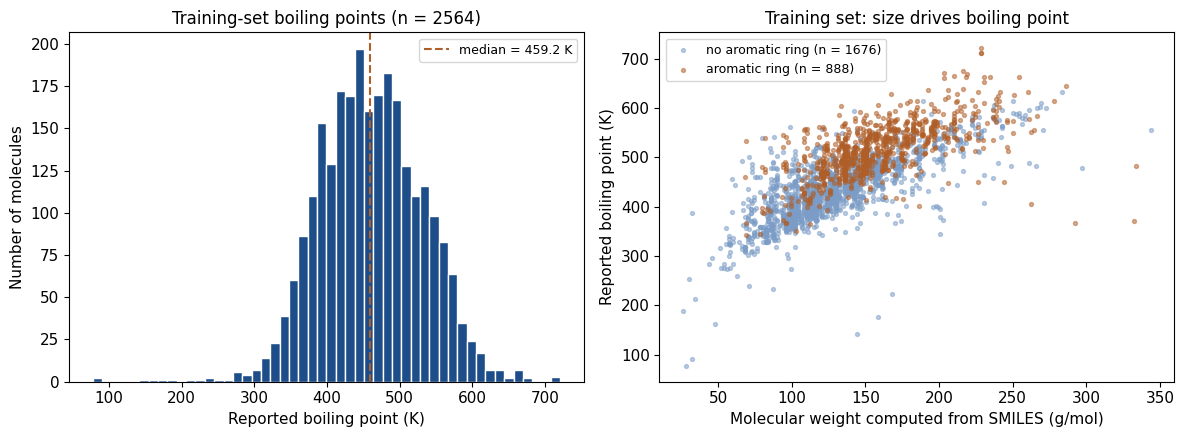

Spearman correlation of MW with BP on training molecules: 0.75 (n = 2564)


In [6]:
data = molecules.merge(splits[['inchikey', 'split']], on='inchikey', validate='one_to_one')
train_view = data[data['split'] == 'train'].reset_index(drop=True)
train_mols = [Chem.MolFromSmiles(s) for s in train_view['canonical_smiles']]
train_view['MolWt_rdkit'] = [Descriptors.MolWt(m) for m in train_mols]
train_view['aromatic'] = [any(a.GetIsAromatic() for a in m.GetAtoms()) for m in train_mols]
display(train_view['BP'].describe().to_frame('training BP (K)').T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(train_view['BP'], bins=50, color='#1D4E89', edgecolor='white')
axes[0].axvline(train_view.BP.median(), color='#B05E27', ls='--', label=f'median = {train_view.BP.median():.1f} K')
axes[0].set(xlabel='Reported boiling point (K)', ylabel='Number of molecules',
            title=f'Training-set boiling points (n = {len(train_view)})')
axes[0].legend()
for flag, color, label in [(False, '#7a9cc6', 'no aromatic ring'), (True, '#B05E27', 'aromatic ring')]:
    sub = train_view[train_view['aromatic'] == flag]
    axes[1].scatter(sub.MolWt_rdkit, sub.BP, s=8, alpha=0.5, c=color, label=f'{label} (n = {len(sub)})')
axes[1].set(xlabel='Molecular weight computed from SMILES (g/mol)', ylabel='Reported boiling point (K)',
            title='Training set: size drives boiling point')
axes[1].legend()
fig.tight_layout()
save_fig(fig, 'step4_train_bp_distribution_and_molecular_weight.png')
plt.show()
rho = train_view[['MolWt_rdkit', 'BP']].corr(method='spearman').iloc[0, 1]
print(f'Spearman correlation of MW with BP on training molecules: {rho:.2f} (n = {len(train_view)})')

### Flag chemically suspicious training entries

Code Summary: Lists training molecules whose boiling point is implausibly low for their size and molecules whose repeated reports disagree by more than 25 K, so the cleaning decisions in Step 5 are based on evidence.

In [7]:
low = train_view[(train_view['BP'] < 250) & (train_view['MolWt_rdkit'] > 70)]
conflict = train_view[train_view['BP_spread'] > 25]
print(f'Training molecules with BP < 250 K despite MW > 70 g/mol: {len(low)} of {len(train_view)}')
display(low[['canonical_smiles', 'CAS', 'BP', 'MolWt_rdkit']].sort_values('BP').round(1))
print(f'Training molecules whose repeated reports differ by > 25 K: {len(conflict)}')
display(conflict[['canonical_smiles', 'CAS', 'n_reports', 'BP_min', 'BP_max', 'BP']].round(1))

Training molecules with BP < 250 K despite MW > 70 g/mol: 5 of 2564


,canonical_smiles,CAS,BP,MolWt_rdkit
2506,CC(C)CC(=O)OC(C)C,32665-23-9,141.8,144.2
88,CCCCOC(=O)CC(C)C,109-19-3,175.7,158.2
2182,CCCCCC(=O)C=CC(C)C,32064-75-8,223.5,168.3
2057,CCC(C)CN,36272-22-7;96-15-1,232.6,87.2
1038,ClCl,7782-50-5,239.5,70.9


Training molecules whose repeated reports differ by > 25 K: 3


,canonical_smiles,CAS,n_reports,BP_min,BP_max,BP
1478,CC=C(C)C(C)=CC,18265-39-9;21293-01-6;2417-88-1,3,377.2,407.2,386.6
2057,CCC(C)CN,36272-22-7;96-15-1,2,96.5,368.7,232.6
2204,C=C(C)C1CCC(C)CC1,1124-25-0;1124-27-2;1879-07-8,3,441.7,516.2,446.0


**What Step 4 found.** Missing SMILES are the only eligibility failure (no salts, unparsable strings or non-finite targets), and the chemistry is narrow: only C, H, N, O, S and Cl appear — no F, Br, I, P or Si — which already limits where the model can be trusted. Several "duplicates" are cis/trans isomers whose SMILES lack stereo; a 2D model cannot distinguish them, so collapsing them and keeping them in one split is correct. Among training labels, a handful are physically implausible: e.g. isopropyl isovalerate at 141.8 K, butyl isovalerate at 175.7 K and a C11 enone at 223.5 K. Adding 273.15 gives ≈415 K, ≈449 K and ≈497 K — plausible boiling points for these esters and ketone — which strongly suggests Celsius values stored as kelvin. 2-Methylbutylamine has two reports, 96.5 K and 368.7 K; only the second is physically sensible. Not every low value is an error: chlorine (Cl₂, 239.5 K) is correct. Step 5 handles these with an explicit, physics-based rule.

<h2 style="color:#1D4E89;">Step 5: Data Carpentry</h2>

<h3 style="color:#B05E27;">Decision and rationale</h3>

**Hypothesis 1 — a group-contribution model is a useful physics prior.** The **Joback method** estimates boiling point as 198 K plus a fixed increment for each functional group (e.g. +92.9 K per alcohol OH, +23.6 K per CH₃). The **Stein–Brown correction** fixes Joback's known overestimate for large molecules. This estimate needs no training data, so we can use it three ways and test each: (a) as a physics-only baseline, (b) as an input feature, and (c) to detect label errors — a reported BP 150 K away from the estimate is far beyond typical group-contribution error (~20 K), and if adding 273.15 K brings it within 40 K, a Celsius/kelvin mix-up is the most plausible explanation.

**Cleaning policy.** Rules are applied to **training labels**: correct likely Celsius entries (+273.15 K), and drop rows that are implausible for other reasons (probably reduced-pressure values or transcription errors) or whose repeated reports disagree by > 25 K. *Validation labels are flagged but never changed*, so validation measures performance on the data as it really is; the test set is inspected with the same rule only in Step 10. The original Parquet is untouched; a cleaned working file is saved separately.

**Hypothesis 2 — features that encode intermolecular forces carry the signal.** Boiling point reflects how strongly molecules stick together: dispersion forces (size, surface area, polarizability), dipoles, hydrogen bonding (OH, NH, COOH), and shape (branched molecules pack less well and boil lower). We compare: a **curated physchem set** (~35 descriptors such as surface area, molar refractivity as a polarizability proxy, H-bond donors/acceptors, polar surface area, shape indices, Joback estimate); **Joback group counts**; **all ~210 RDKit 2D descriptors**; **Morgan count fingerprints** (counts of circular atom environments, a generic substructure encoding); and combinations. All features are computed from SMILES by a stateless featurizer, so nothing is learned from labels at this stage. A fixed gradient-boosting "probe" model compares feature sets on validation data.

### Write the reusable SMILES featurizer module

Code Summary: Saves the featurization code to a small Python module in the output folder so the saved model can be reloaded later. It implements the approximate Joback groups, the Stein-Brown correction, curated and full RDKit descriptors, Morgan count fingerprints and two physics-aware model wrappers.

In [8]:
%%writefile {FEATURE_MODULE}
"""SMILES-only features and small model wrappers for the one-shot boiling-point workflow.

Generated by 01_boiling_point/prompt_test/03_P1_BP_One_Shot_Workflow.ipynb. Every feature is
computed from the SMILES string alone, so the same code runs at training and prediction time.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from rdkit import Chem, RDLogger
from rdkit.Chem import Crippen, Descriptors, rdFingerprintGenerator, rdMolDescriptors
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone

RDLogger.DisableLog("rdApp.*")

# Joback (1987) boiling-point group increments in K; Tb = 198 K + sum(increments).
JOBACK_TB = {
    "CH3": 23.58, "CH2": 22.88, "CH": 21.74, "C": 18.25,
    "=CH2": 18.18, "=CH": 24.96, "=C": 24.14, "=C=": 26.15, "#CH": 9.20, "#C": 27.38,
    "ring_CH2": 27.15, "ring_CH": 21.78, "ring_C": 21.32, "ring_=CH": 26.73, "ring_=C": 31.01,
    "F": -0.03, "Cl": 38.13, "Br": 66.86, "I": 93.84,
    "OH_alcohol": 92.88, "OH_phenol": 76.34, "O": 22.42, "ring_O": 31.22,
    "C=O": 76.75, "ring_C=O": 94.97, "CHO": 72.24, "COOH": 169.09, "COO": 81.10, "=O_other": -10.50,
    "NH2": 73.23, "NH": 50.17, "ring_NH": 52.82, "N": 11.74, "-N=": 74.60, "ring_-N=": 57.55,
    "=NH": 83.08, "CN": 125.66, "NO2": 152.54, "SH": 63.56, "S": 68.78, "ring_S": 52.10,
}
# Multi-atom groups are assigned first so their atoms are not counted twice.
_MULTI_ATOM_GROUPS = [
    ("COOH", Chem.MolFromSmarts("[CX3](=O)[OX2H1]"), 3),
    ("COO", Chem.MolFromSmarts("[CX3](=O)[OX2][#6]"), 3),
    ("NO2", Chem.MolFromSmarts("[$([NX3](=O)=O),$([NX3+](=O)[O-])](~[OX1])~[OX1]"), 3),
    ("CN", Chem.MolFromSmarts("[CX2]#[NX1]"), 2),
    ("CHO", Chem.MolFromSmarts("[CX3H1]=[OX1]"), 2),
]


def parse_smiles(smiles: str) -> Chem.Mol:
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        raise ValueError(f"Could not parse SMILES: {smiles!r}")
    return mol


def _single_atom_group(atom: Chem.Atom, used: set) -> str | None:
    """Approximate atom-centred Joback group for an atom not in a multi-atom group."""
    sym, h, ring = atom.GetSymbol(), atom.GetTotalNumHs(), atom.IsInRing()
    bonds = list(atom.GetBonds())
    n_double = sum(b.GetBondType() == Chem.BondType.DOUBLE for b in bonds)
    n_triple = sum(b.GetBondType() == Chem.BondType.TRIPLE for b in bonds)
    if sym == "C":
        if atom.GetIsAromatic():
            return "ring_=CH" if h else "ring_=C"
        if n_triple:
            return "#CH" if h else "#C"
        if n_double >= 2:
            return "=C="
        if n_double == 1:
            carbonyl_o = [b.GetOtherAtom(atom) for b in bonds
                          if b.GetBondType() == Chem.BondType.DOUBLE and b.GetOtherAtom(atom).GetSymbol() == "O"]
            if carbonyl_o:
                used.update(o.GetIdx() for o in carbonyl_o)
                return "ring_C=O" if ring else "C=O"
            if ring:
                return "ring_=CH" if h else "ring_=C"
            return {2: "=CH2", 1: "=CH", 0: "=C"}.get(h)
        if ring:
            return {2: "ring_CH2", 1: "ring_CH", 0: "ring_C"}.get(h)
        return {4: "CH3", 3: "CH3", 2: "CH2", 1: "CH", 0: "C"}.get(h)
    if sym in ("F", "Cl", "Br", "I"):
        return sym
    if sym == "O":
        if n_double:
            return "=O_other"
        if h >= 1:
            on_aromatic = any(n.GetIsAromatic() for n in atom.GetNeighbors())
            return "OH_phenol" if on_aromatic else "OH_alcohol"
        return "ring_O" if (ring or atom.GetIsAromatic()) else "O"
    if sym == "N":
        if atom.GetIsAromatic():
            return "ring_NH" if h else "ring_-N="
        if n_triple:
            return None
        if n_double:
            return "=NH" if h else ("ring_-N=" if ring else "-N=")
        return {3: "NH2", 2: "NH2", 1: "ring_NH" if ring else "NH", 0: "N"}.get(h)
    if sym == "S":
        if h:
            return "SH"
        return "ring_S" if (ring or atom.GetIsAromatic()) else "S"
    return None


def joback_group_counts(mol: Chem.Mol) -> tuple[dict, int]:
    """Return (group counts, number of heavy atoms with no Joback group)."""
    counts = dict.fromkeys(JOBACK_TB, 0)
    used: set = set()
    for key, query, n_core in _MULTI_ATOM_GROUPS:
        for match in mol.GetSubstructMatches(query):
            core = match[:n_core]
            if not used.intersection(core):
                counts[key] += 1
                used.update(core)
    unassigned = 0
    for atom in mol.GetAtoms():
        if atom.GetIdx() in used:
            continue
        key = _single_atom_group(atom, used)
        if key is None:
            unassigned += 1
        else:
            counts[key] += 1
    return counts, unassigned


def stein_brown(tb_joback):
    """Stein & Brown (1994) correction of Joback's systematic overestimate for large molecules."""
    tb = np.asarray(tb_joback, dtype=float)
    return np.where(tb <= 700, tb - 94.84 + 0.5577 * tb - 0.0007705 * tb**2, tb + 282.7 - 0.5209 * tb)


_SMARTS = {name: Chem.MolFromSmarts(s) for name, s in {
    "nOH": "[OX2H]", "nNH": "[NX3;H1,H2;!$(NC=O)]", "nCOOH": "[CX3](=O)[OX2H1]",
    "nAmide": "[CX3](=O)[NX3]", "nCH3": "[CH3]", "nCarbonyl": "[CX3]=[OX1]",
}.items()}


def physchem_descriptors(mol: Chem.Mol) -> dict:
    """Curated descriptors chosen for the intermolecular forces that set boiling point."""
    heavy = mol.GetNumHeavyAtoms()
    symbols = [a.GetSymbol() for a in mol.GetAtoms()]
    groups, unassigned = joback_group_counts(mol)
    tb = 198.0 + sum(JOBACK_TB[k] * v for k, v in groups.items())
    d = {
        "MolWt": Descriptors.MolWt(mol), "HeavyAtoms": heavy,
        "LabuteASA": rdMolDescriptors.CalcLabuteASA(mol), "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "MolMR": Crippen.MolMR(mol), "MolLogP": Crippen.MolLogP(mol),
        "HBD": rdMolDescriptors.CalcNumHBD(mol), "HBA": rdMolDescriptors.CalcNumHBA(mol),
        "RotBonds": rdMolDescriptors.CalcNumRotatableBonds(mol), "Rings": rdMolDescriptors.CalcNumRings(mol),
        "AromaticRings": rdMolDescriptors.CalcNumAromaticRings(mol),
        "FracCSP3": rdMolDescriptors.CalcFractionCSP3(mol),
        "Kappa1": rdMolDescriptors.CalcKappa1(mol), "Kappa2": rdMolDescriptors.CalcKappa2(mol),
        "Kappa3": rdMolDescriptors.CalcKappa3(mol) if heavy > 3 else 0.0,
        "Chi0v": rdMolDescriptors.CalcChi0v(mol), "Chi1v": rdMolDescriptors.CalcChi1v(mol),
        "HallKierAlpha": rdMolDescriptors.CalcHallKierAlpha(mol),
        "BalabanJ": Descriptors.BalabanJ(mol) if mol.GetNumBonds() else 0.0,
        "BertzCT": Descriptors.BertzCT(mol), "ValenceElectrons": Descriptors.NumValenceElectrons(mol),
        "nCl": symbols.count("Cl"), "nN": symbols.count("N"), "nO": symbols.count("O"), "nS": symbols.count("S"),
        "nHalogen": sum(s in ("F", "Cl", "Br", "I") for s in symbols),
    }
    d.update({name: len(mol.GetSubstructMatches(q)) for name, q in _SMARTS.items()})
    d.update({"JobackTb": tb, "JobackSB": float(stein_brown(tb)), "JobackUnassigned": unassigned})
    return d


def rdkit_descriptors(mol: Chem.Mol) -> dict:
    """All RDKit 2D descriptors; Ipc is log-scaled because it spans many orders of magnitude."""
    out = {}
    for name, fn in Descriptors.descList:
        try:
            value = float(fn(mol))
        except Exception:  # a few descriptors fail on tiny molecules
            value = np.nan
        out[name] = np.log1p(value) if name == "Ipc" and np.isfinite(value) else value
    return out


def featurize_smiles(smiles, morgan_radius: int = 2, morgan_size: int = 2048) -> pd.DataFrame:
    """One row per SMILES with prefixed feature families: phys__, jbg__, rd__, mg__."""
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=morgan_radius, fpSize=morgan_size)
    rows, fps = [], []
    for smi in smiles:
        mol = parse_smiles(smi)
        row = {f"phys__{k}": v for k, v in physchem_descriptors(mol).items()}
        row.update({f"jbg__{k}": v for k, v in joback_group_counts(mol)[0].items()})
        row.update({f"rd__{k}": v for k, v in rdkit_descriptors(mol).items()})
        rows.append(row)
        fps.append(gen.GetCountFingerprintAsNumPy(mol).astype(np.float32))
    frame = pd.DataFrame(rows)
    morgan = pd.DataFrame(np.vstack(fps), columns=[f"mg__{i}" for i in range(morgan_size)])
    frame = pd.concat([frame, morgan], axis=1)
    return frame.replace([np.inf, -np.inf], np.nan).astype(float)


class SmilesFeaturizer(TransformerMixin, BaseEstimator):
    """Stateless transformer: SMILES strings -> feature DataFrame (nothing is learned)."""

    def __init__(self, morgan_radius: int = 2, morgan_size: int = 2048):
        self.morgan_radius = morgan_radius
        self.morgan_size = morgan_size

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        smiles = X.iloc[:, 0] if isinstance(X, pd.DataFrame) else X
        return featurize_smiles(list(np.ravel(smiles)), self.morgan_radius, self.morgan_size)


class ColumnSubset(TransformerMixin, BaseEstimator):
    """Keep feature columns whose names start with any of the given prefixes."""

    def __init__(self, prefixes=("rd__",)):
        self.prefixes = prefixes

    def fit(self, X, y=None):
        self.columns_ = [c for c in X.columns if c.startswith(tuple(self.prefixes))]
        if not self.columns_:
            raise ValueError(f"No columns match {self.prefixes}")
        return self

    def transform(self, X):
        return X[self.columns_]


class PhysicsEstimate(RegressorMixin, BaseEstimator):
    """Predicts the group-contribution estimate directly; fit() learns nothing."""

    def __init__(self, base_col: str = "phys__JobackSB"):
        self.base_col = base_col

    def fit(self, X, y=None):
        return self

    def predict(self, X):
        return X[self.base_col].to_numpy(dtype=float)


class ResidualOnPhysics(RegressorMixin, BaseEstimator):
    """Learns y - (group-contribution estimate), then adds the estimate back at prediction."""

    def __init__(self, estimator=None, base_col: str = "phys__JobackSB"):
        self.estimator = estimator
        self.base_col = base_col

    def fit(self, X, y):
        base = X[self.base_col].to_numpy(dtype=float)
        self.estimator_ = clone(self.estimator).fit(X, np.asarray(y, dtype=float) - base)
        return self

    def predict(self, X):
        return self.estimator_.predict(X) + X[self.base_col].to_numpy(dtype=float)

Overwriting /home/ejmcmk/research/workshop_test/2026-avs-ml-vibe-coding-workshop/01_boiling_point/outputs/one_shot_p1/bp_one_shot_features.py


### Import the featurizer and sanity-check the group-contribution estimate

Code Summary: Imports the module and compares the Joback and Stein-Brown estimates with handbook boiling points for familiar molecules, verifying the implementation before it is used for cleaning or modeling.

In [9]:
if str(OUT) not in sys.path:
    sys.path.insert(0, str(OUT))
import bp_one_shot_features as bpf
bpf = importlib.reload(bpf)

handbook = pd.DataFrame({
    'molecule': ['n-hexane', 'n-decane', 'toluene', 'naphthalene', 'acetone', '1-butanol', 'chlorobenzene'],
    'smiles': ['CCCCCC', 'CCCCCCCCCC', 'Cc1ccccc1', 'c1ccc2ccccc2c1', 'CC(C)=O', 'CCCCO', 'Clc1ccccc1'],
    'handbook_BP_K': [341.9, 447.3, 383.8, 491.1, 329.2, 390.9, 404.9]})
est = pd.DataFrame([bpf.physchem_descriptors(bpf.parse_smiles(s)) for s in handbook['smiles']])
handbook['Joback_K'] = est['JobackTb'].round(1)
handbook['SteinBrown_K'] = est['JobackSB'].round(1)
handbook['SB_error_K'] = (handbook['SteinBrown_K'] - handbook['handbook_BP_K']).round(1)
display(handbook)
print(f'Mean |error| on these handbook molecules: Joback {np.abs(handbook.Joback_K - handbook.handbook_BP_K).mean():.1f} K, '
      f'Stein-Brown {handbook.SB_error_K.abs().mean():.1f} K (n = {len(handbook)})')

,molecule,smiles,handbook_BP_K,Joback_K,SteinBrown_K,SB_error_K
0,n-hexane,CCCCCC,341.9,336.7,342.3,0.4
1,n-decane,CCCCCCCCCC,447.3,428.2,430.9,-16.4
2,toluene,Cc1ccccc1,383.8,386.2,391.9,8.1
3,naphthalene,c1ccc2ccccc2c1,491.1,473.9,470.3,-20.8
4,acetone,CC(C)=O,329.2,321.9,326.8,-2.4
5,1-butanol,CCCCO,390.9,383.1,388.8,-2.1
6,chlorobenzene,Clc1ccccc1,404.9,400.8,405.7,0.8


Mean |error| on these handbook molecules: Joback 9.0 K, Stein-Brown 7.3 K (n = 7)


### Apply physics-based label checks to training and validation

Code Summary: Computes the Stein-Brown estimate for each training and validation molecule, flags labels that deviate by more than 150 K or whose repeated reports conflict, and records the cleaning action. Only training labels are corrected or dropped.

In [10]:
QC_DEV_K, QC_CELSIUS_TOL_K, QC_SPREAD_K = 150.0, 40.0, 25.0

def label_qc(frame):
    """Flag labels inconsistent with the group-contribution estimate (rules fixed before use)."""
    sb = np.array([bpf.physchem_descriptors(bpf.parse_smiles(s))['JobackSB'] for s in frame['canonical_smiles']])
    bp = frame['BP'].to_numpy(float)
    dev = bp - sb
    celsius = (dev < -QC_DEV_K) & (np.abs(bp + 273.15 - sb) <= QC_CELSIUS_TOL_K)
    flag = np.select([celsius, dev < -QC_DEV_K, dev > QC_DEV_K, frame['BP_spread'].to_numpy() > QC_SPREAD_K],
                     ['likely_celsius', 'implausibly_low', 'implausibly_high', 'conflicting_reports'], default='ok')
    return pd.DataFrame({'joback_sb_K': sb, 'deviation_K': dev, 'qc_flag': flag}, index=frame.index)

work = data[data['split'] != 'test'].copy()          # test labels are not inspected until Step 10
work = work.join(label_qc(work))
is_train = work['split'].eq('train')
work['qc_action'] = 'keep'
work.loc[is_train & work.qc_flag.eq('likely_celsius'), 'qc_action'] = 'correct_add_273.15'
work.loc[is_train & work.qc_flag.isin(['implausibly_low', 'implausibly_high', 'conflicting_reports']), 'qc_action'] = 'drop_from_training'
work.loc[~is_train & work.qc_flag.ne('ok'), 'qc_action'] = 'keep_label_flag_only'
work['BP_model'] = np.where(work.qc_action.eq('correct_add_273.15'), work['BP'] + 273.15, work['BP'])
work.loc[work.qc_action.eq('drop_from_training'), 'BP_model'] = np.nan

display(pd.crosstab(work['qc_flag'], work['split']))
display(work[work.qc_flag.ne('ok')].sort_values(['split', 'qc_flag'])[
    ['split', 'canonical_smiles', 'BP', 'joback_sb_K', 'deviation_K', 'BP_spread', 'qc_flag', 'qc_action']].round(1))

split,train,validation
qc_flag,,
conflicting_reports,2,0
implausibly_high,4,2
implausibly_low,9,3
likely_celsius,6,1
ok,2543,314


,split,canonical_smiles,BP,joback_sb_K,deviation_K,BP_spread,qc_flag,qc_action
1847,train,CC=C(C)C(C)=CC,386.6,396.0,-9.3,30.0,conflicting_reports,drop_from_training
2752,train,C=C(C)C1CCC(C)CC1,446.0,441.1,4.9,74.4,conflicting_reports,drop_from_training
312,train,CC1CCS(=O)(=O)C1,550.0,362.0,188.0,0.0,implausibly_high,drop_from_training
817,train,CS(C)(=O)=O,511.0,295.4,215.6,0.0,implausibly_high,drop_from_training
900,train,O=S1(=O)CCCC1,558.0,343.3,214.7,0.0,implausibly_high,drop_from_training
1525,train,CCS(=O)(=O)N(C)C,513.0,357.1,155.9,0.0,implausibly_high,drop_from_training
0,train,c1ccc(C(c2ccccc2)c2ccccc2)cc1,449.0,624.6,-175.6,0.0,implausibly_low,drop_from_training
20,train,O=C(O)c1cc([N+](=O)[O-])cc([N+](=O)[O-])c1Cl,513.7,708.0,-194.3,0.0,implausibly_low,drop_from_training
108,train,NS(=O)(=O)c1ccc(Nc2nc(-c3ccccn3)cs2)cc1,371.0,729.2,-358.2,0.0,implausibly_low,drop_from_training
1029,train,CC(CO)C(C)(C)O,347.1,504.8,-157.7,0.0,implausibly_low,drop_from_training


### Save the cleaned working file

Code Summary: Writes the training and validation molecules with raw labels, group-contribution estimates, flags, actions and the label used for modeling to a new CSV, leaving the source Parquet unchanged.

In [11]:
CLEAN_PATH = OUT / 'bp_cleaned_train_validation.csv'
work.to_csv(CLEAN_PATH, index=False)
train_all = work[work['split'] == 'train'].reset_index(drop=True)       # every training molecule, raw labels
keep_mask = train_all['BP_model'].notna().to_numpy()
train_df = train_all[keep_mask].reset_index(drop=True)                    # cleaned training set
val_df = work[work['split'] == 'validation'].reset_index(drop=True)
print(work['qc_action'].value_counts().to_string())
print(f'\nTraining molecules: {len(train_all)} -> {len(train_df)} after cleaning '
      f'({int((train_all.qc_action == "correct_add_273.15").sum())} corrected, {int((~keep_mask).sum())} dropped)')
print(f'Validation molecules: {len(val_df)} (labels unchanged; {int((val_df.qc_flag != "ok").sum())} flagged)')
print('Saved', rel(CLEAN_PATH))

qc_action
keep                    2857
drop_from_training        15
keep_label_flag_only       6
correct_add_273.15         6

Training molecules: 2564 -> 2549 after cleaning (6 corrected, 15 dropped)
Validation molecules: 320 (labels unchanged; 6 flagged)
Saved 01_boiling_point/outputs/one_shot_p1/bp_cleaned_train_validation.csv


### Engineer SMILES-derived features

Code Summary: Runs the stateless featurizer on all training and validation molecules, reports the size of each feature family, and saves an aligned modeling table with labels and descriptor features. Morgan columns are omitted from that file because they are cheap to recompute.

In [12]:
t0 = time.perf_counter()
featurizer = bpf.SmilesFeaturizer()
X_train_all = featurizer.transform(train_all['canonical_smiles'])
X_train = X_train_all[keep_mask].reset_index(drop=True)
X_val = featurizer.transform(val_df['canonical_smiles'])
y_train = train_df['BP_model'].to_numpy(float)
y_train_raw = train_all['BP'].to_numpy(float)
y_val = val_df['BP'].to_numpy(float)
print(f'Featurized {len(X_train_all) + len(X_val)} molecules in {time.perf_counter() - t0:.1f} s')
display(pd.Series({p: sum(c.startswith(p) for c in X_train.columns) for p in ('phys__', 'jbg__', 'rd__', 'mg__')},
                  name='columns').to_frame().rename(index={'phys__': 'curated physchem (incl. Joback estimate)',
                  'jbg__': 'Joback group counts', 'rd__': 'all RDKit 2D descriptors', 'mg__': 'Morgan counts (r=2, 2048)'}))
desc_cols = [c for c in X_train.columns if not c.startswith('mg__')]
modeling = pd.concat([
    pd.concat([train_df[['inchikey', 'canonical_smiles', 'split']].assign(BP_K=y_train), X_train[desc_cols]], axis=1),
    pd.concat([val_df[['inchikey', 'canonical_smiles', 'split']].assign(BP_K=y_val), X_val[desc_cols]], axis=1)])
modeling.to_parquet(OUT / 'modeling_features_train_validation.parquet', index=False)
print('Saved', rel(OUT / 'modeling_features_train_validation.parquet'), modeling.shape)

Featurized 2884 molecules in 10.4 s


,columns
curated physchem (incl. Joback estimate),35
Joback group counts,41
all RDKit 2D descriptors,210
"Morgan counts (r=2, 2048)",2048


Saved 01_boiling_point/outputs/one_shot_p1/modeling_features_train_validation.parquet (2869, 290)


### Compare feature sets with a fixed probe model

Code Summary: Trains the same gradient-boosting probe on each feature set using cleaned training labels, scores it on validation molecules, and plots validation MAE against the training-median baseline.

n_train = 2549, n_validation = 320; training-median baseline validation MAE = 58.2 K


,feature_set,n_features,train_MAE_K,val_MAE_K,val_RMSE_K,val_R2,fit_s
0,rdkit_joback,252,2.450,13.492,29.330,0.840,2.059
1,rdkit,210,2.502,13.620,27.024,0.864,1.914
2,rdkit_joback_morgan,2300,2.436,13.651,29.055,0.843,11.573
3,physchem,35,4.829,15.771,31.238,0.818,1.145
4,joback_groups,41,11.365,18.117,31.473,0.815,1.277
5,morgan,2048,9.572,18.782,32.057,0.808,9.801


Saved figure: 01_boiling_point/outputs/one_shot_p1/figures/step5_feature_set_comparison_validation_mae.png


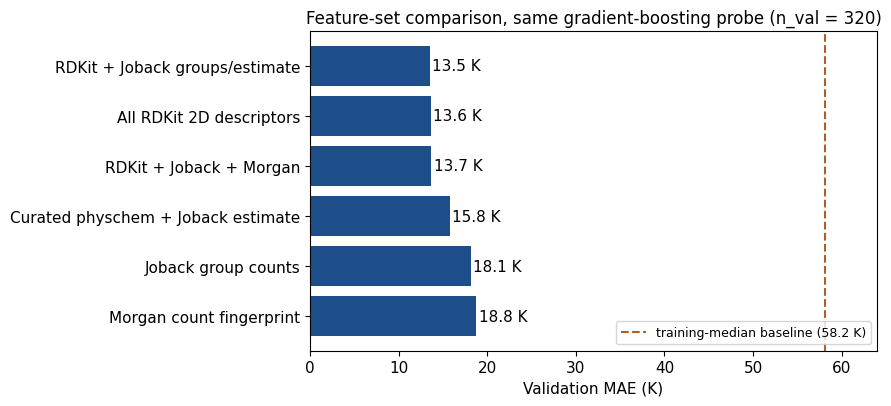

In [13]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline

FEATURE_SETS = {
    'joback_groups': ('jbg__',),
    'physchem': ('phys__',),
    'morgan': ('mg__',),
    'rdkit': ('rd__',),
    'rdkit_joback': ('rd__', 'jbg__', 'phys__JobackSB'),
    'rdkit_joback_morgan': ('rd__', 'jbg__', 'phys__JobackSB', 'mg__'),
}
FEATURE_LABELS = {'joback_groups': 'Joback group counts', 'physchem': 'Curated physchem + Joback estimate',
                  'morgan': 'Morgan count fingerprint', 'rdkit': 'All RDKit 2D descriptors',
                  'rdkit_joback': 'RDKit + Joback groups/estimate', 'rdkit_joback_morgan': 'RDKit + Joback + Morgan'}
median_val = metrics(y_val, np.full_like(y_val, np.median(y_train)))
rows = []
for key, prefixes in FEATURE_SETS.items():
    t0 = time.perf_counter()
    probe = Pipeline([('select', bpf.ColumnSubset(prefixes)),
                      ('hgb', HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=SEED))])
    probe.fit(X_train, y_train)
    tr, va = metrics(y_train, probe.predict(X_train)), metrics(y_val, probe.predict(X_val))
    rows.append({'feature_set': key, 'n_features': len(probe['select'].columns_), 'train_MAE_K': tr['MAE_K'],
                 'val_MAE_K': va['MAE_K'], 'val_RMSE_K': va['RMSE_K'], 'val_R2': va['R2'],
                 'fit_s': time.perf_counter() - t0})
feature_comparison = pd.DataFrame(rows).sort_values('val_MAE_K').reset_index(drop=True)
feature_comparison.to_csv(OUT / 'step5_feature_set_comparison.csv', index=False)
print(f'n_train = {len(y_train)}, n_validation = {len(y_val)}; training-median baseline validation MAE = {median_val["MAE_K"]:.1f} K')
display(feature_comparison.round(3))

fig, ax = plt.subplots(figsize=(9, 4.2))
fc = feature_comparison.iloc[::-1]
ax.barh([FEATURE_LABELS[k] for k in fc.feature_set], fc.val_MAE_K, color='#1D4E89')
for i, v in enumerate(fc.val_MAE_K):
    ax.text(v + 0.3, i, f'{v:.1f} K', va='center')
ax.axvline(median_val['MAE_K'], color='#B05E27', ls='--', label=f'training-median baseline ({median_val["MAE_K"]:.1f} K)')
ax.set(xlabel='Validation MAE (K)', xlim=(0, median_val['MAE_K'] * 1.1),
       title=f'Feature-set comparison, same gradient-boosting probe (n_val = {len(y_val)})')
ax.legend(loc='lower right')
fig.tight_layout()
save_fig(fig, 'step5_feature_set_comparison_validation_mae.png')
plt.show()

### Show which curated descriptors carry the signal

Code Summary: Fits the probe on the interpretable curated descriptors and measures permutation importance on validation molecules, meaning how much validation MAE rises when one descriptor is randomly shuffled.

Saved figure: 01_boiling_point/outputs/one_shot_p1/figures/step5_physchem_permutation_importance.png


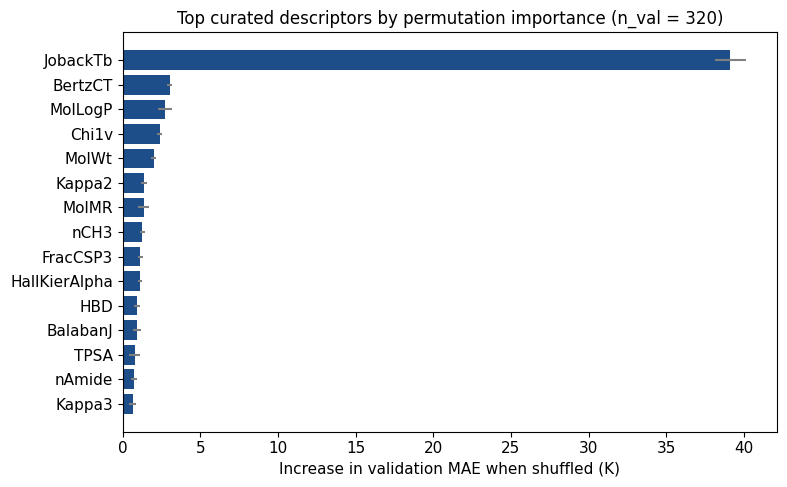

,feature,MAE_increase_K,sd_K
0,JobackTb,39.12,1.00
1,BertzCT,3.02,0.18
2,MolLogP,2.74,0.43
3,Chi1v,2.40,0.16
4,MolWt,1.99,0.14
5,Kappa2,1.36,0.19
6,MolMR,1.35,0.38
7,nCH3,1.28,0.16
8,FracCSP3,1.14,0.16
9,HallKierAlpha,1.14,0.12


In [14]:
from sklearn.inspection import permutation_importance

phys_cols = [c for c in X_train.columns if c.startswith('phys__')]
probe = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=SEED).fit(X_train[phys_cols], y_train)
pi = permutation_importance(probe, X_val[phys_cols], y_val, scoring='neg_mean_absolute_error',
                            n_repeats=5, random_state=SEED)
imp = (pd.DataFrame({'feature': [c.removeprefix('phys__') for c in phys_cols],
                     'MAE_increase_K': pi.importances_mean, 'sd_K': pi.importances_std})
       .sort_values('MAE_increase_K', ascending=False).reset_index(drop=True))
imp.to_csv(OUT / 'step5_physchem_permutation_importance.csv', index=False)
top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.feature, top.MAE_increase_K, xerr=top.sd_K, color='#1D4E89', ecolor='gray')
ax.set(xlabel='Increase in validation MAE when shuffled (K)',
       title=f'Top curated descriptors by permutation importance (n_val = {len(y_val)})')
fig.tight_layout()
save_fig(fig, 'step5_physchem_permutation_importance.png')
plt.show()
display(imp.head(10).round(2))

**Feature takeaways.** With the same boosting probe, **all RDKit 2D descriptors** carry most of the signal (validation MAE 13.6 K) and adding the Joback groups/estimate gives 13.5 K — a difference well within validation noise (n = 320). The curated 35-descriptor set reaches 15.8 K, while Joback group counts alone (18.1 K) and Morgan fingerprints alone (18.8 K) are clearly weaker: fingerprints record which local substructures are present but describe overall size and shape — which dominate boiling point — only indirectly. Appending 2,048 Morgan columns to the descriptors did not help (13.7 K) and took about five times longer to fit. Permutation importance confirms the physics prior: shuffling the Joback estimate raises validation MAE by ~39 K, far more than any other descriptor; next come molecular complexity (BertzCT), lipophilicity/polarity (MolLogP), a size-and-branching connectivity index (Chi1v) and molecular weight. **Decision:** carry `rdkit_joback` forward and re-test `rdkit` alone and `+ Morgan` with the final model family in Step 7.

**Reviewer note on the label rule (added after reviewing the full run).** The rule is only as good as the Joback estimate behind it. It flagged genuinely wrong labels (the Celsius esters, 2-methylbutylamine at 96.5 K, 1-amino-1-methylcyclopentane at exactly 273.15 K), but it also over-flagged real values where Joback is weak: four sulfones/sulfonamides (e.g. dimethyl sulfone, 511 K, and sulfolane, 558 K, are correct — Joback has no sulfone group) were dropped from training, cyanogen (252 K, correct) is flagged in validation, and tetranitromethane's correct 399 K label was "corrected" to 672 K because four nitro increments make the estimate far too high. These affect 5 of 2,549 training molecules, and Step 7's raw-label ablation shows the final model family is insensitive to cleaning, so the rule was left unchanged; a better group-contribution prior is listed as a next step.

<h2 style="color:#1D4E89;">Step 6: Algorithm</h2>

<h3 style="color:#B05E27;">Decision and rationale</h3>

**Candidates and why.** Every model is wrapped in one scikit-learn `Pipeline` that starts by selecting a feature family (`ColumnSubset`), so all candidates share the same interface — `fit(features, BP)` / `predict(features)` — and the same training-only preprocessing.

- **Training-median baseline** — predicts one number for everything; any useful model must beat it by a wide margin.
- **Joback/Stein–Brown estimate** — pure physics, zero fitted parameters; tells us how much machine learning adds over a classical method.
- **Ridge regression** — the simple, interpretable reference: a linear model with a penalty on large coefficients (α chosen by internal cross-validation on training data). Run on the curated physchem set so its coefficients map to chemistry.
- **Random forest** and **histogram gradient boosting** — tree ensembles that capture non-linear effects and interactions (e.g. an OH group matters more in a small molecule than a large one), and are robust to unscaled, heavy-tailed descriptors.
- **Support vector regression (SVR, RBF kernel)** — predicts a new molecule from its similarity to training molecules in standardized descriptor space; smooth and often strong on small, descriptor-based chemistry datasets.
- **Small neural network (MLP)** — a flexible non-linear model; included as a check, though it usually needs more data than ~2,500 molecules.

**Hypothesis 3 — learn the residual on top of physics.** `ResidualOnPhysics` trains a model on *BP − Stein–Brown estimate* and adds the estimate back. If the physics captures the bulk trend, the ML model only has to learn the corrections. This is tested for Ridge, gradient boosting and SVR. *Not chosen:* a graph neural network trained from scratch (typically needs more molecules and minutes of CPU training for an uncertain gain here) and pretrained chemical language models (no downloads allowed); both are reference notebooks in `examples/`.

### Define the candidate model builders

Code Summary: Defines one builder that returns a uniform model specification with a name, family, feature set, estimator, editable settings and notes, then lists the planned candidates with their default settings.

In [15]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.svm import SVR

DEFAULTS = {
    'median_baseline': {},
    'joback_stein_brown': {},
    'ridge': {'alphas': [float(a) for a in np.logspace(-3, 3, 13)]},
    'random_forest': {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 0.3},
    'hist_gradient_boosting': {'max_iter': 800, 'learning_rate': 0.05, 'min_samples_leaf': 10, 'max_features': 0.5},
    'svr': {'C': 100.0, 'epsilon': 2.0, 'gamma': 'scale'},
    'mlp': {'hidden_layer_sizes': (256, 128), 'alpha': 1e-2, 'max_iter': 500},
}

def _pipe(feature_set, *steps):
    return Pipeline([('select', bpf.ColumnSubset(FEATURE_SETS[feature_set])), *steps])

def build_model(family, feature_set='rdkit_joback', residual=False, **overrides):
    """Return a uniform spec: name, family, feature_set, residual, estimator, settings, notes."""
    s = {**DEFAULTS[family], **overrides}
    impute = ('impute', SimpleImputer(strategy='median'))
    if family == 'median_baseline':
        est, feature_set = DummyRegressor(strategy='median'), 'none'
    elif family == 'joback_stein_brown':
        est, feature_set = bpf.PhysicsEstimate(), 'joback_estimate'
    elif family == 'ridge':
        est = _pipe(feature_set, impute, ('drop_constant', VarianceThreshold()), ('scale', StandardScaler()),
                    ('ridge', RidgeCV(alphas=s['alphas'])))
    elif family == 'random_forest':
        est = _pipe(feature_set, impute, ('rf', RandomForestRegressor(
            n_estimators=s['n_estimators'], min_samples_leaf=s['min_samples_leaf'],
            max_features=s['max_features'], n_jobs=4, random_state=SEED)))
    elif family == 'hist_gradient_boosting':
        est = _pipe(feature_set, ('hgb', HistGradientBoostingRegressor(random_state=SEED, **s)))
    elif family == 'svr':
        est = _pipe(feature_set, impute, ('drop_constant', VarianceThreshold()), ('scale', StandardScaler()),
                    ('svr', SVR(kernel='rbf', **s)))
    elif family == 'mlp':
        net = _pipe(feature_set, impute, ('drop_constant', VarianceThreshold()),
                    ('gaussianize', QuantileTransformer(output_distribution='normal', random_state=SEED)),
                    ('mlp', MLPRegressor(early_stopping=True, random_state=SEED, **s)))
        est = TransformedTargetRegressor(regressor=net, transformer=StandardScaler())
    else:
        raise ValueError(family)
    if residual:
        est = bpf.ResidualOnPhysics(est)
    name = f"{family}{'_residual' if residual else ''}__{feature_set}"
    return {'name': name, 'family': family, 'feature_set': feature_set, 'residual': residual,
            'estimator': est, 'settings': s}

display(pd.DataFrame([{'family': f, 'default settings': json.dumps(v)} for f, v in DEFAULTS.items()]))

,family,default settings
0,median_baseline,{}
1,joback_stein_brown,{}
2,ridge,"{""alphas"": [0.001, 0.0031622776601683794, 0.01..."
3,random_forest,"{""n_estimators"": 300, ""min_samples_leaf"": 2, ""..."
4,hist_gradient_boosting,"{""max_iter"": 800, ""learning_rate"": 0.05, ""min_..."
5,svr,"{""C"": 100.0, ""epsilon"": 2.0, ""gamma"": ""scale""}"
6,mlp,"{""hidden_layer_sizes"": [256, 128], ""alpha"": 0...."


<h2 style="color:#1D4E89;">Step 7: Experiment</h2>

<h3 style="color:#B05E27;">Decision and rationale</h3>

**Fair comparisons.** Every experiment uses the same saved split, the same cleaned training molecules and the same untouched validation labels, so differences come from the model, setting or feature choice alone. The split estimates how well the model generalizes to **new molecules drawn from the same chemical space** as the NIST table — not to new element types or very different chemistry.

**Tracking.** Each experiment gets a numbered folder (`experiment_001`, …) with `metadata.json` (settings, notes, metrics, counts), `predictions.csv` (train and validation only) and, for neural networks, `training_history.csv`; one running `experiment_summary.csv` collects all results. No test predictions are made here.

**Plan.** (1) Model families on the `rdkit_joback` feature set chosen in Step 5, plus the Ridge reference on curated physchem descriptors; (2) residual-on-physics variants; (3) a **cleaning ablation** — the strongest families retrained on raw, uncleaned labels to check that cleaning actually helps; (4) a **feature ablation** for the best family. With ~320 validation molecules, differences under ~0.5 K are within noise, so we favour simpler options when results are close.

### Verify the saved molecular splits

Code Summary: Reloads the split file, asserts that no connectivity skeleton, InChIKey or canonical SMILES is shared between splits, and confirms the modeling tables contain only training and validation molecules.

In [16]:
saved = pd.read_csv(SPLIT_PATH)
for key in ('skeleton', 'inchikey', 'canonical_smiles'):
    sets = {s: set(saved.loc[saved['split'] == s, key]) for s in ('train', 'validation', 'test')}
    for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
        assert not sets[a] & sets[b], f'{key} shared between {a} and {b}'
assert set(train_df['inchikey']) <= set(saved.loc[saved.split == 'train', 'inchikey'])
assert set(val_df['inchikey']) <= set(saved.loc[saved.split == 'validation', 'inchikey'])
assert len(X_train) == len(y_train) == len(train_df) and len(X_val) == len(y_val) == len(val_df)
display(pd.DataFrame({'molecules in split file': saved['split'].value_counts(),
                      'used for modeling now': pd.Series({'train': len(train_df), 'validation': len(val_df), 'test': 0})}
                     ).reindex(['train', 'validation', 'test']))
print('All splits are disjoint by skeleton, InChIKey and canonical SMILES.')
print('Imputation, variance filtering, scaling and model weights are fit inside each Pipeline on training rows only;')
print('the featurizer is stateless. Test molecules are reserved: no features or predictions until Step 10.')

,molecules in split file,used for modeling now
train,2564,2549
validation,320,320
test,321,0


All splits are disjoint by skeleton, InChIKey and canonical SMILES.
Imputation, variance filtering, scaling and model weights are fit inside each Pipeline on training rows only;
the featurizer is stateless. Test molecules are reserved: no features or predictions until Step 10.


### Build the experiment tracker

Code Summary: Creates a fresh experiments folder and helper functions that fit a model specification, save metadata, train and validation predictions and any neural-network training history, append to a summary table, and look up or rank experiments.

In [17]:
shutil.rmtree(EXP_DIR, ignore_errors=True)       # fresh numbering on every full run
EXP_DIR.mkdir(parents=True)
EXP_SUMMARY = EXP_DIR / 'experiment_summary.csv'
FITTED, VAL_PRED, SPECS = {}, {}, {}

def _loss_curve(est):
    for attr in ('regressor_', 'estimator_'):
        if hasattr(est, attr):
            return _loss_curve(getattr(est, attr))
    last = est[-1] if isinstance(est, Pipeline) else est
    return getattr(last, 'loss_curve_', None), getattr(last, 'validation_scores_', None)

def run_experiment(spec, notes, X_fit=None, y_fit=None, label_policy='cleaned'):
    X_fit = X_train if X_fit is None else X_fit
    y_fit = y_train if y_fit is None else y_fit
    exp_id = f'experiment_{len(FITTED) + 1:03d}'
    t0 = time.perf_counter()
    est = sklearn.base.clone(spec['estimator']).fit(X_fit, y_fit)
    fit_s = time.perf_counter() - t0
    p_tr, p_va = est.predict(X_fit), est.predict(X_val)
    m_tr, m_va = metrics(y_fit, p_tr), metrics(y_val, p_va)
    folder = EXP_DIR / exp_id
    folder.mkdir()
    meta = {'experiment_id': exp_id, 'name': spec['name'], 'family': spec['family'],
            'feature_set': spec['feature_set'], 'residual_on_physics': spec['residual'],
            'settings': spec['settings'], 'label_policy': label_policy, 'notes': notes,
            'split_file': rel(SPLIT_PATH), 'seed': SEED, 'train_metrics': m_tr, 'validation_metrics': m_va,
            'fit_seconds': round(fit_s, 2), 'test_metrics': 'not computed during experimentation'}
    (folder / 'metadata.json').write_text(json.dumps(meta, indent=2, default=str))
    fit_ids = train_df if X_fit is X_train else train_all
    pd.concat([pd.DataFrame({'split': 'train', 'inchikey': fit_ids['inchikey'], 'y_true_K': y_fit, 'y_pred_K': p_tr}),
               pd.DataFrame({'split': 'validation', 'inchikey': val_df['inchikey'], 'y_true_K': y_val, 'y_pred_K': p_va})]
              ).to_csv(folder / 'predictions.csv', index=False)
    loss, val_scores = _loss_curve(est)
    if loss is not None:
        hist = pd.DataFrame({'epoch': np.arange(1, len(loss) + 1), 'train_loss_scaled': loss})
        if val_scores is not None:
            hist['internal_early_stopping_R2'] = val_scores
        hist.to_csv(folder / 'training_history.csv', index=False)
    row = {'experiment_id': exp_id, 'name': spec['name'], 'family': spec['family'], 'feature_set': spec['feature_set'],
           'residual': spec['residual'], 'label_policy': label_policy, 'n_train': m_tr['n'], 'n_val': m_va['n'],
           'train_MAE_K': m_tr['MAE_K'], 'val_MAE_K': m_va['MAE_K'], 'val_RMSE_K': m_va['RMSE_K'],
           'val_R2': m_va['R2'], 'fit_s': round(fit_s, 2), 'notes': notes}
    pd.DataFrame([row]).to_csv(EXP_SUMMARY, mode='a', header=not EXP_SUMMARY.exists(), index=False)
    FITTED[exp_id], VAL_PRED[exp_id], SPECS[exp_id] = est, p_va, spec
    print(f'{exp_id}  {spec["name"]:<48} train MAE {m_tr["MAE_K"]:6.2f} K | val MAE {m_va["MAE_K"]:6.2f} K | {fit_s:5.1f} s')
    return exp_id

def lookup_experiment(exp_id):
    return json.loads((EXP_DIR / exp_id / 'metadata.json').read_text())

def summarize_experiments():
    return pd.read_csv(EXP_SUMMARY).sort_values('val_MAE_K').reset_index(drop=True)

print('Tracker ready at', rel(EXP_DIR))

Tracker ready at 01_boiling_point/outputs/one_shot_p1/experiments


### Compare model families on the same split

Code Summary: Runs the baseline, the physics-only estimate, the Ridge reference and the non-linear model families, with and without residual learning on the group-contribution estimate, then shows the ranked validation results.

In [18]:
family_runs = [
    (build_model('median_baseline'), 'Training-median baseline.'),
    (build_model('joback_stein_brown'), 'Physics-only group-contribution estimate; nothing fitted.'),
    (build_model('ridge', 'physchem'), 'Interpretable linear reference on curated descriptors.'),
    (build_model('ridge', 'physchem', residual=True), 'H3: linear correction on top of the physics estimate.'),
    (build_model('ridge', 'rdkit_joback'), 'Linear model on the full descriptor set (fairness check).'),
    (build_model('random_forest'), 'Tree ensemble, averaged deep trees.'),
    (build_model('hist_gradient_boosting'), 'Boosted trees, Step 5 probe family with regularized defaults.'),
    (build_model('hist_gradient_boosting', residual=True), 'H3: boosted trees learn the physics residual.'),
    (build_model('svr'), 'RBF-kernel SVR on standardized descriptors.'),
    (build_model('svr', residual=True), 'H3: SVR learns the physics residual.'),
    (build_model('mlp'), 'Two-layer neural network with early stopping on an internal training holdout.'),
]
for spec, note in family_runs:
    run_experiment(spec, note)
summary_cols = ['experiment_id', 'name', 'label_policy', 'train_MAE_K', 'val_MAE_K', 'val_RMSE_K', 'val_R2', 'fit_s']
display(summarize_experiments()[summary_cols].round(3))

experiment_001  median_baseline__none                            train MAE  56.07 K | val MAE  58.16 K |   0.0 s
experiment_002  joback_stein_brown__joback_estimate              train MAE  19.14 K | val MAE  21.90 K |   0.0 s


experiment_003  ridge__physchem                                  train MAE  14.95 K | val MAE  17.34 K |   0.0 s
experiment_004  ridge_residual__physchem                         train MAE  14.95 K | val MAE  17.34 K |   0.0 s


experiment_005  ridge__rdkit_joback                              train MAE  10.47 K | val MAE  14.01 K |   0.2 s


experiment_006  random_forest__rdkit_joback                      train MAE   5.54 K | val MAE  15.34 K |   2.6 s


experiment_007  hist_gradient_boosting__rdkit_joback             train MAE   0.97 K | val MAE  13.13 K |   3.5 s


experiment_008  hist_gradient_boosting_residual__rdkit_joback    train MAE   0.92 K | val MAE  12.72 K |   3.4 s


experiment_009  svr__rdkit_joback                                train MAE   4.96 K | val MAE  13.40 K |   0.7 s


experiment_010  svr_residual__rdkit_joback                       train MAE   4.29 K | val MAE  12.20 K |   0.7 s


experiment_011  mlp__rdkit_joback                                train MAE   7.71 K | val MAE  15.84 K |   4.2 s


,experiment_id,name,label_policy,train_MAE_K,val_MAE_K,val_RMSE_K,val_R2,fit_s
0,experiment_010,svr_residual__rdkit_joback,cleaned,4.290,12.205,29.767,0.835,0.72
1,experiment_008,hist_gradient_boosting_residual__rdkit_joback,cleaned,0.918,12.720,28.144,0.852,3.35
2,experiment_007,hist_gradient_boosting__rdkit_joback,cleaned,0.970,13.134,27.916,0.855,3.45
3,experiment_009,svr__rdkit_joback,cleaned,4.957,13.399,32.059,0.808,0.75
4,experiment_005,ridge__rdkit_joback,cleaned,10.473,14.006,29.411,0.839,0.24
5,experiment_006,random_forest__rdkit_joback,cleaned,5.537,15.335,30.572,0.826,2.61
6,experiment_011,mlp__rdkit_joback,cleaned,7.706,15.837,27.984,0.854,4.16
7,experiment_003,ridge__physchem,cleaned,14.952,17.339,31.491,0.815,0.03
8,experiment_004,ridge_residual__physchem,cleaned,14.951,17.340,31.491,0.815,0.02
9,experiment_002,joback_stein_brown__joback_estimate,cleaned,19.139,21.900,39.578,0.708,0.00


### Run the cleaning and feature-set ablations

Code Summary: Retrains the two best model families on raw, uncleaned training labels to test whether label cleaning helps, and retrains the best family on alternative feature sets to test whether the chosen features earn their place.

In [19]:
ranked = summarize_experiments()
learned = ranked[ranked.label_policy.eq('cleaned') & ~ranked.family.isin(['median_baseline', 'joback_stein_brown'])]
top_families = learned.drop_duplicates('family').head(2)
for _, r in top_families.iterrows():
    spec = build_model(r.family, r.feature_set, residual=bool(r.residual))
    run_experiment(spec, 'Cleaning ablation: raw training labels (no Celsius fix, no drops).',
                   X_fit=X_train_all, y_fit=y_train_raw, label_policy='raw')
best = top_families.iloc[0]
for fs in ('physchem', 'rdkit', 'rdkit_joback_morgan'):
    if fs != best.feature_set:
        run_experiment(build_model(best.family, fs, residual=bool(best.residual)), f'Feature ablation for the best family: {fs}.')
display(summarize_experiments()[summary_cols].round(3))

experiment_012  svr_residual__rdkit_joback                       train MAE   5.36 K | val MAE  11.96 K |   0.8 s


experiment_013  hist_gradient_boosting_residual__rdkit_joback    train MAE   1.08 K | val MAE  14.02 K |   3.5 s


experiment_014  svr_residual__physchem                           train MAE   8.44 K | val MAE  13.84 K |   0.4 s


experiment_015  svr_residual__rdkit                              train MAE   4.57 K | val MAE  12.01 K |   0.7 s


experiment_016  svr_residual__rdkit_joback_morgan                train MAE   2.99 K | val MAE  16.51 K |   6.8 s


,experiment_id,name,label_policy,train_MAE_K,val_MAE_K,val_RMSE_K,val_R2,fit_s
0,experiment_012,svr_residual__rdkit_joback,raw,5.357,11.958,29.369,0.839,0.77
1,experiment_015,svr_residual__rdkit,cleaned,4.568,12.010,29.404,0.839,0.71
2,experiment_010,svr_residual__rdkit_joback,cleaned,4.290,12.205,29.767,0.835,0.72
3,experiment_008,hist_gradient_boosting_residual__rdkit_joback,cleaned,0.918,12.720,28.144,0.852,3.35
4,experiment_007,hist_gradient_boosting__rdkit_joback,cleaned,0.970,13.134,27.916,0.855,3.45
5,experiment_009,svr__rdkit_joback,cleaned,4.957,13.399,32.059,0.808,0.75
6,experiment_014,svr_residual__physchem,cleaned,8.443,13.838,31.135,0.819,0.40
7,experiment_005,ridge__rdkit_joback,cleaned,10.473,14.006,29.411,0.839,0.24
8,experiment_013,hist_gradient_boosting_residual__rdkit_joback,raw,1.085,14.024,30.009,0.832,3.48
9,experiment_006,random_forest__rdkit_joback,cleaned,5.537,15.335,30.572,0.826,2.61


### Plot the experiment comparison

Code Summary: Draws every experiment's validation MAE as a bar with its training MAE as a dot, marks the training-median baseline, and saves the figure.

Saved figure: 01_boiling_point/outputs/one_shot_p1/figures/step7_experiment_comparison_mae.png


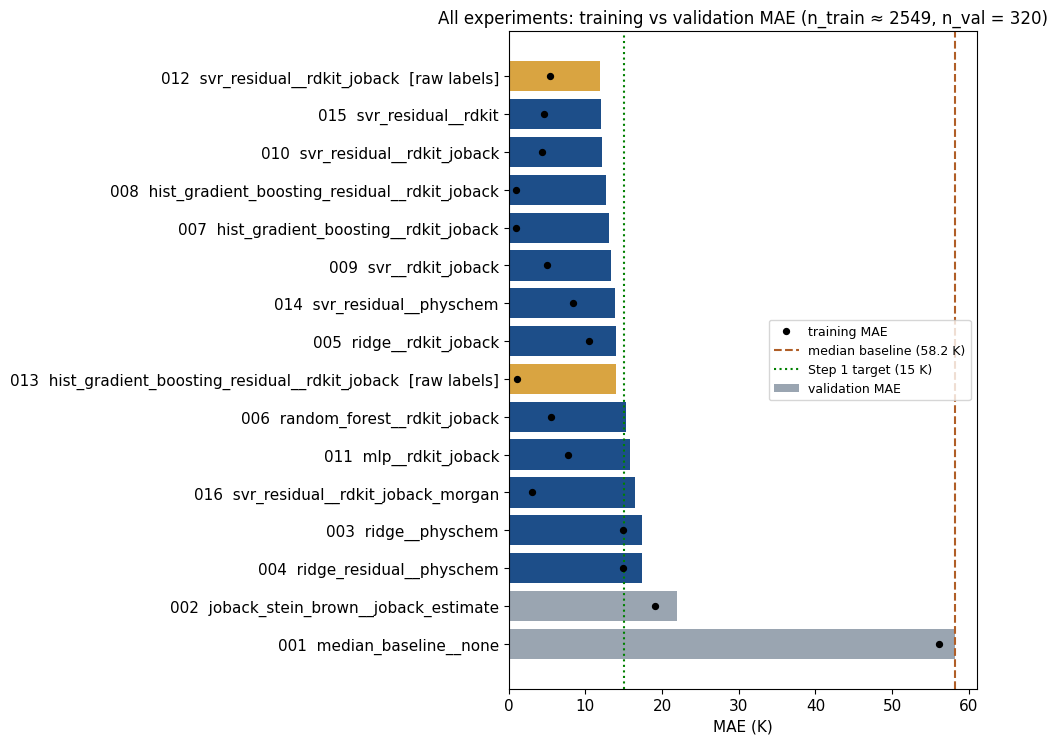

In [20]:
summ = summarize_experiments().iloc[::-1]
colors = np.where(summ.family.isin(['median_baseline', 'joback_stein_brown']), '#9aa5b1',
                  np.where(summ.label_policy.eq('raw'), '#d9a441', '#1D4E89'))
fig, ax = plt.subplots(figsize=(10, 0.38 * len(summ) + 1.5))
labels = [f'{e.split("_")[1]}  {n}{"  [raw labels]" if p == "raw" else ""}' for e, n, p in zip(summ.experiment_id, summ.name, summ.label_policy)]
ax.barh(labels, summ.val_MAE_K, color=colors, label='validation MAE')
ax.scatter(summ.train_MAE_K, labels, color='black', marker='o', s=18, zorder=3, label='training MAE')
base_mae = summ.loc[summ.family.eq('median_baseline'), 'val_MAE_K'].iloc[0]
ax.axvline(base_mae, color='#B05E27', ls='--', label=f'median baseline ({base_mae:.1f} K)')
ax.axvline(15, color='green', ls=':', label='Step 1 target (15 K)')
ax.set(xlabel='MAE (K)', title=f'All experiments: training vs validation MAE (n_train ≈ {len(y_train)}, n_val = {len(y_val)})')
ax.legend(loc='center right')
fig.tight_layout()
save_fig(fig, 'step7_experiment_comparison_mae.png')
plt.show()

**What Step 7 shows.** 
- Every learned model beats the training-median baseline (58.2 K) and the physics-only Stein–Brown estimate (21.9 K, nothing fitted); the Ridge reference on curated descriptors reaches 17.3 K.
- **Residual learning (Hypothesis 3) helps the non-linear models:** SVR improves from 13.4 to 12.2 K and boosted trees from 13.1 to 12.7 K when they learn the correction to the Stein–Brown estimate. For Ridge it changes nothing (17.34 K both), as expected: the estimate is already a linear input, so subtracting it only shifts one coefficient by exactly 1.
- SVR has a smaller train/validation gap (~8 K) than boosted trees (~12 K), which nearly memorize the training set (training MAE < 1 K). Random forest (15.3 K) and the MLP (15.8 K) trail, consistent with ~2,500 molecules being small for a neural network.
- **Cleaning ablation — mixed result:** cleaning improved boosted trees by 1.3 K (14.0 → 12.7 K) but not SVR (raw labels 11.96 K vs cleaned 12.20 K, within noise). SVR's ε-insensitive loss grows only linearly with error, so a few wildly wrong labels barely pull it, whereas squared-error boosting is pulled much harder. Cleaning is kept because the corrected/dropped labels are mostly demonstrably wrong and it clearly helps the second-best family.
- **Feature ablation for residual SVR:** RDKit descriptors alone (12.0 K) ≈ RDKit + Joback columns (12.2 K); the curated set is worse (13.8 K) and adding Morgan counts hurts (16.5 K) because 2,048 sparse, standardized count columns swamp the RBF distance. The physics prior works best as the *baseline being corrected*, not as extra input columns. Step 8 therefore analyzes residual SVR on RDKit descriptors (experiment_015) as the best cleaned-label model.

<h2 style="color:#1D4E89;">Step 8: Analysis</h2>

<h3 style="color:#B05E27;">Decision and rationale</h3>

**What:** rank experiments by validation MAE, then study the best model's errors from four angles: the **train/validation gap** (how much the model memorizes), **error versus boiling-point range** (does it struggle at the extremes?), **errors by functional group** (which chemistry is hard, and is it simply rare in training?), and **applicability domain** — how similar each validation molecule is to its nearest training molecule (Tanimoto similarity of Morgan fingerprints, 0 = nothing shared, 1 = identical). These views point to one focused improvement for Step 9. The test set remains sealed.

### Rank experiments and inspect the train/validation gap

Code Summary: Sorts all experiments by validation MAE, adds the gap between validation and training MAE, and selects the best cleaned-label experiment and the Ridge reference for detailed analysis.

In [21]:
ranked = summarize_experiments()
ranked['gap_K'] = ranked['val_MAE_K'] - ranked['train_MAE_K']
display(ranked[['experiment_id', 'name', 'label_policy', 'train_MAE_K', 'val_MAE_K', 'gap_K', 'val_RMSE_K', 'val_R2']].round(2))
BEST_ID = ranked[ranked.label_policy.eq('cleaned')].iloc[0]['experiment_id']
REF_ID = ranked[ranked.name.eq('ridge__physchem')].iloc[0]['experiment_id']
BASE_ID = ranked[ranked.family.eq('median_baseline')].iloc[0]['experiment_id']
best_pred, ref_pred = VAL_PRED[BEST_ID], VAL_PRED[REF_ID]
print(f'Best: {BEST_ID} {lookup_experiment(BEST_ID)["name"]} | Ridge reference: {REF_ID} | baseline: {BASE_ID}')

,experiment_id,name,label_policy,train_MAE_K,val_MAE_K,gap_K,val_RMSE_K,val_R2
0,experiment_012,svr_residual__rdkit_joback,raw,5.36,11.96,6.60,29.37,0.84
1,experiment_015,svr_residual__rdkit,cleaned,4.57,12.01,7.44,29.40,0.84
2,experiment_010,svr_residual__rdkit_joback,cleaned,4.29,12.20,7.92,29.77,0.83
3,experiment_008,hist_gradient_boosting_residual__rdkit_joback,cleaned,0.92,12.72,11.80,28.14,0.85
4,experiment_007,hist_gradient_boosting__rdkit_joback,cleaned,0.97,13.13,12.16,27.92,0.85
5,experiment_009,svr__rdkit_joback,cleaned,4.96,13.40,8.44,32.06,0.81
6,experiment_014,svr_residual__physchem,cleaned,8.44,13.84,5.40,31.14,0.82
7,experiment_005,ridge__rdkit_joback,cleaned,10.47,14.01,3.53,29.41,0.84
8,experiment_013,hist_gradient_boosting_residual__rdkit_joback,raw,1.08,14.02,12.94,30.01,0.83
9,experiment_006,random_forest__rdkit_joback,cleaned,5.54,15.34,9.80,30.57,0.83


Best: experiment_015 svr_residual__rdkit | Ridge reference: experiment_003 | baseline: experiment_001


### Plot validation parity and error by boiling-point range

Code Summary: Plots predicted against reported validation boiling points for the best model and the Ridge reference, and shows mean absolute error within boiling-point bands with molecule counts.

Saved figure: 01_boiling_point/outputs/one_shot_p1/figures/step8_validation_parity_and_error_by_bp_range.png


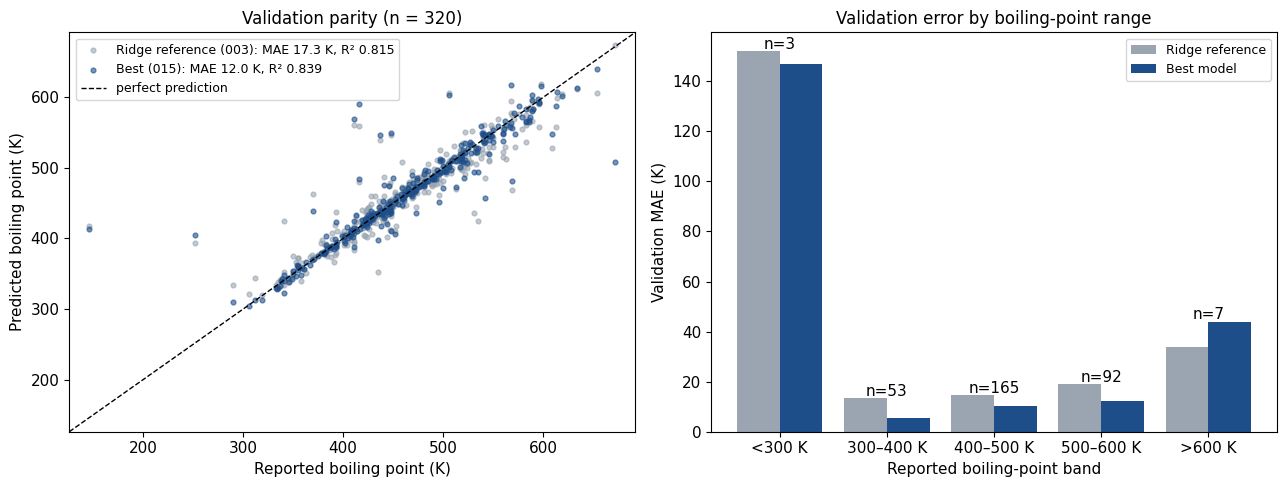

,best,ridge,n
band,,,
<300,146.8,152.0,3
300–400,5.7,13.3,53
400–500,10.2,14.6,165
500–600,12.1,18.9,92
>600,43.9,33.7,7


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
lims = [min(y_val.min(), best_pred.min()) - 20, max(y_val.max(), best_pred.max()) + 20]
for pred, name, color in [(ref_pred, f'Ridge reference ({REF_ID[-3:]})', '#9aa5b1'), (best_pred, f'Best ({BEST_ID[-3:]})', '#1D4E89')]:
    m = metrics(y_val, pred)
    axes[0].scatter(y_val, pred, s=12, alpha=0.6, c=color, label=f'{name}: MAE {m["MAE_K"]:.1f} K, R² {m["R2"]:.3f}')
axes[0].plot(lims, lims, 'k--', lw=1, label='perfect prediction')
axes[0].set(xlim=lims, ylim=lims, xlabel='Reported boiling point (K)', ylabel='Predicted boiling point (K)',
            title=f'Validation parity (n = {len(y_val)})')
axes[0].legend(loc='upper left')
bands = pd.cut(y_val, [0, 300, 400, 500, 600, 800], labels=['<300', '300–400', '400–500', '500–600', '>600'])
band = pd.DataFrame({'band': bands, 'best': np.abs(best_pred - y_val), 'ridge': np.abs(ref_pred - y_val)}).groupby('band', observed=False)
band_mae, band_n = band.mean(), band.size()
x = np.arange(len(band_mae))
axes[1].bar(x - 0.2, band_mae['ridge'], 0.4, color='#9aa5b1', label='Ridge reference')
axes[1].bar(x + 0.2, band_mae['best'], 0.4, color='#1D4E89', label='Best model')
for i, n in enumerate(band_n):
    axes[1].text(i, max(band_mae.iloc[i].max(), 0) + 1, f'n={n}', ha='center')
axes[1].set_xticks(x, [f'{b} K' for b in band_mae.index])
axes[1].set(xlabel='Reported boiling-point band', ylabel='Validation MAE (K)', title='Validation error by boiling-point range')
axes[1].legend()
fig.tight_layout()
save_fig(fig, 'step8_validation_parity_and_error_by_bp_range.png')
plt.show()
display(pd.concat([band_mae.round(1), band_n.rename('n')], axis=1))

### Measure the applicability domain

Code Summary: Computes each validation molecule's highest Tanimoto similarity to any training molecule and shows how validation error changes as molecules become less similar to the training set.

,n,MAE_K,median_abs_err_K
similarity band,,,
<0.4,21,20.6,7.1
0.4–0.6,165,13.1,5.1
0.6–0.8,82,7.2,4.5
≥0.8,52,12.8,3.5


Saved figure: 01_boiling_point/outputs/one_shot_p1/figures/step8_validation_error_vs_training_similarity.png


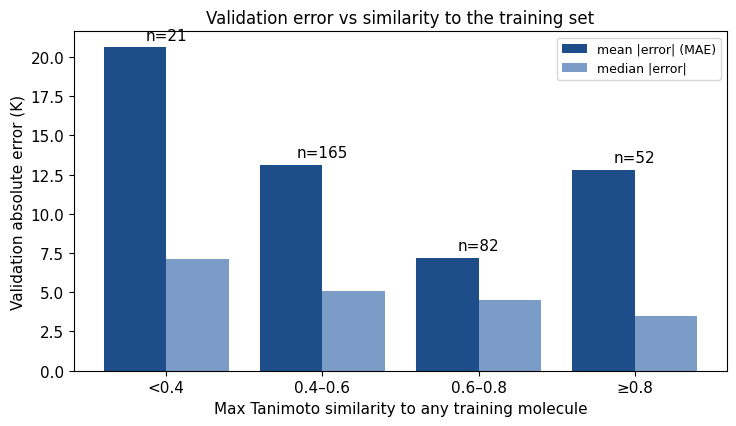

In [23]:
FP_GEN = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
TRAIN_FPS = [FP_GEN.GetFingerprint(Chem.MolFromSmiles(s)) for s in train_df['canonical_smiles']]

def max_train_similarity(smiles_list):
    return np.array([max(DataStructs.BulkTanimotoSimilarity(FP_GEN.GetFingerprint(Chem.MolFromSmiles(s)), TRAIN_FPS))
                     for s in smiles_list])

val_sim = max_train_similarity(val_df['canonical_smiles'])
sim_band = pd.cut(val_sim, [0, 0.4, 0.6, 0.8, 1.0001], labels=['<0.4', '0.4–0.6', '0.6–0.8', '≥0.8'])
ad = pd.DataFrame({'similarity band': sim_band, 'abs_error_K': np.abs(best_pred - y_val)}).groupby('similarity band', observed=False)['abs_error_K']
ad_table = pd.DataFrame({'n': ad.size(), 'MAE_K': ad.mean().round(1), 'median_abs_err_K': ad.median().round(1)})
display(ad_table)
fig, ax = plt.subplots(figsize=(7.5, 4.4))
x = np.arange(len(ad_table))
ax.bar(x - 0.2, ad_table.MAE_K, 0.4, color='#1D4E89', label='mean |error| (MAE)')
ax.bar(x + 0.2, ad_table.median_abs_err_K, 0.4, color='#7a9cc6', label='median |error|')
for i, (n, v) in enumerate(zip(ad_table.n, ad_table.MAE_K)):
    ax.text(i, (0 if np.isnan(v) else v) + 0.5, f'n={n}', ha='center')
ax.set_xticks(x, ad_table.index.astype(str))
ax.set(xlabel='Max Tanimoto similarity to any training molecule', ylabel='Validation absolute error (K)',
       title='Validation error vs similarity to the training set')
ax.legend()
fig.tight_layout()
save_fig(fig, 'step8_validation_error_vs_training_similarity.png')
plt.show()

### Find chemically meaningful failure patterns

Code Summary: Tags validation molecules with functional groups using substructure patterns and compares error, average bias and training coverage for each group, revealing which chemistry is hardest and whether it is rare in training.

In [24]:
FG_SMARTS = {
    'carboxylic acid': '[CX3](=O)[OX2H1]', 'aliphatic alcohol': '[CX4][OX2H]', 'phenol': 'c[OX2H]',
    'amine (non-amide N–H/N)': '[NX3;!$(NC=O);!$(N-a);!$([N+])]', 'aniline-type N': '[NX3;!$(NC=O);$(N-a)]',
    'amide': '[CX3](=O)[NX3]', 'ester': '[#6][CX3](=O)[OX2][#6]', 'ketone': '[#6][CX3](=O)[#6]',
    'aldehyde': '[CX3H1](=O)', 'ether': '[OX2;!$(OC=O)]([#6])[#6]', 'nitrile': 'C#N', 'nitro': '[N+](=O)[O-]',
    'organochlorine': '[Cl]', 'sulfur compound': '[#16]', 'aromatic N heterocycle': 'n', 'aromatic ring': 'a',
}
FG_Q = {k: Chem.MolFromSmarts(v) for k, v in FG_SMARTS.items()}

def fg_matrix(smiles):
    ms = [Chem.MolFromSmiles(s) for s in smiles]
    out = pd.DataFrame({k: [m.HasSubstructMatch(q) for m in ms] for k, q in FG_Q.items()})
    out['hydrocarbon only'] = [all(a.GetSymbol() == 'C' for a in m.GetAtoms()) for m in ms]
    return out

fg_val, fg_train = fg_matrix(val_df['canonical_smiles']), fg_matrix(train_df['canonical_smiles'])
err = best_pred - y_val
rows = [{'group': g, 'n_train': int(fg_train[g].sum()), 'n_val': int(fg_val[g].sum()),
         'val_MAE_best_K': np.abs(err[fg_val[g]]).mean(), 'mean_signed_error_K': err[fg_val[g]].mean(),
         'val_MAE_ridge_K': np.abs(ref_pred - y_val)[fg_val[g]].mean()} for g in fg_val.columns if fg_val[g].sum() >= 5]
fg_table = pd.DataFrame(rows).sort_values('val_MAE_best_K', ascending=False).reset_index(drop=True)
fg_table.to_csv(OUT / 'step8_validation_error_by_functional_group.csv', index=False)
print(f'Overall best-model validation MAE: {np.abs(err).mean():.1f} K (n = {len(err)}); groups with n_val >= 5:')
display(fg_table.round(1))

Overall best-model validation MAE: 12.0 K (n = 320); groups with n_val >= 5:


,group,n_train,n_val,val_MAE_best_K,mean_signed_error_K,val_MAE_ridge_K
0,nitrile,71,11,35.5,15.0,44.4
1,ester,262,32,19.2,6.2,24.6
2,amide,45,5,17.3,-15.3,22.5
3,ether,339,35,15.6,3.9,20.8
4,sulfur compound,135,25,13.8,-7.0,19.0
5,phenol,95,8,13.7,4.0,21.4
6,organochlorine,302,41,12.2,4.3,18.1
7,aliphatic alcohol,297,48,11.6,5.5,16.1
8,aniline-type N,130,13,11.4,-4.2,17.5
9,aromatic N heterocycle,133,16,11.4,-4.3,22.5


### Inspect the largest validation errors

Code Summary: Lists the validation molecules with the largest absolute errors together with their group-contribution estimate, label-quality flag and similarity to training data, to separate model failures from questionable labels.

In [25]:
worst = val_df[['canonical_smiles', 'BP', 'joback_sb_K', 'qc_flag', 'n_reports']].copy()
worst['predicted_K'] = best_pred
worst['error_K'] = best_pred - y_val
worst['max_train_similarity'] = val_sim
worst = worst.reindex(worst['error_K'].abs().sort_values(ascending=False).index).head(12)
display(worst.round(2))

,canonical_smiles,BP,joback_sb_K,qc_flag,n_reports,predicted_K,error_K,max_train_similarity
176,CCC(OC(C)C)OC(C)C,146.50,449.10,likely_celsius,1,414.07,267.57,0.56
98,CCCCCCCCCCCCCC(Cl)Cl,415.65,558.66,ok,1,590.84,175.19,0.55
1,O=c1oc(=O)c2cc3c(=O)oc(=O)c3cc12,671.70,506.81,implausibly_high,1,508.16,-163.54,0.33
209,CCCCCCCCCCCCC(C)C(=O)OC,411.00,576.71,implausibly_low,1,568.95,157.95,1.00
114,N#CC#N,252.00,449.51,implausibly_low,1,404.70,152.70,0.50
174,CCCCC(CO)(CO)CCCC,437.00,581.99,ok,1,545.93,108.93,0.58
146,CCCCCCCCCCCC(=O)OCC,448.00,548.06,ok,1,549.73,101.73,1.00
154,CCCCCCC(c1ccccc1)c1ccccc1,506.00,611.67,ok,1,603.56,97.56,0.95
17,N#CCCCCC#N,568.20,522.25,ok,1,481.94,-86.26,0.91
110,CCCS(=O)(=O)CCC,542.00,390.15,implausibly_high,1,457.63,-84.37,0.32


**Analysis and recommendation.** 
- **Best model:** residual SVR on RDKit descriptors (experiment_015): validation MAE 12.0 K, RMSE 29.4 K, R² 0.839 (n = 320), versus 17.3 K for the Ridge reference. RMSE is much larger than MAE because a few very large misses dominate it.
- **By boiling-point range:** errors are small where data are plentiful (5.7–12.1 K MAE between 300 and 600 K) and large at the sparse extremes: below 300 K (n = 3) the band is dominated by an acetal reported at 146.5 K (flagged as a likely Celsius value), and above 600 K (n = 7) the model under-predicts large fused-ring molecules such as pyromellitic dianhydride (671.7 K reported, 508 K predicted).
- **Applicability domain:** the *median* absolute error falls steadily as similarity to training rises (7.1 → 5.1 → 4.5 → 3.5 K); the mean is noisier because individual mislabeled molecules can land in any band. Radius-2 Morgan similarity cannot tell long-chain homologs apart, so some molecules score 1.00 against a different training homolog.
- **Chemical failure patterns:** nitriles are hardest (35.5 K, n = 11) — cyanogen, N≡C–C≡N (correct label 252 K), is tiny and unlike anything in training, and dinitriles have strong dipole–dipole interactions that additive descriptors capture poorly. Several long-chain esters and halides are strongly over-predicted (1,1-dichlorotetradecane reported at 415.7 K, methyl 2-methyltetradecanoate at 411 K): those values are far too low for C14–C16 compounds and look like reduced-pressure boiling points in the source. Amides are under-predicted on average (−15 K, but only n = 5), plausibly because amide–amide hydrogen bonding is strong and only 45 training molecules contain amides. Hydrocarbons are easiest (5.7 K, n = 80).
- **Half of the 12 largest errors carry a Step 5 label flag.** Some are genuine label errors (the 146.5 K acetal, the C16 ester at 411 K); others (cyanogen, dipropyl sulfone) are real values for chemistry that is rare in training and poorly described by group contributions.

**Recommendation for Step 9:** keep the data, split and features fixed and test one focused idea: **average the residual SVR with the residual boosted-tree model**. The two families make different kinds of errors (smooth kernel similarity vs. axis-aligned splits), so averaging could cancel some of them, and their disagreement may double as an uncertainty signal. Before that, a small bounded search over the SVR's two regularization settings (C and ε) checks that the default is not far from optimal.

<h2 style="color:#1D4E89;">Step 9: Optimization</h2>

<h3 style="color:#B05E27;">Decision and rationale</h3>

**Focused improvement (decided in Step 8):** a bounded search over the residual SVR's regularization — C ∈ {30, 100, 300} × ε ∈ {0.5, 5} K, six runs, with the RBF width left at scikit-learn's `'scale'` default — followed by one ensemble hypothesis: an equal-weight average of the best SVR setting and the best model from a different family (residual boosted trees). *Considered but not run:* a larger random search (validation noise of ~0.5 K would make the winner partly luck) and stacking with a learned meta-model (would need a further data split).

**Decision rule, fixed before running:** within the small grid, keep the setting with the lowest validation MAE (the default is included, so tuning can only be kept if it helps). Adopt the ensemble only if it lowers validation MAE *and* a paired bootstrap over validation molecules shows an improvement in at least 90% of resamples; otherwise keep the simpler single model. Then **freeze** the pipeline: featurizer + chosen model, trained on the cleaned training set only, saved to disk. Nothing after this cell may change it.

### Run a small bounded search for the best family

Code Summary: Tries a predefined grid of a few settings for the best model family on the fixed split and feature set, logs each run in the tracker, and keeps the setting with the lowest validation MAE.

In [26]:
best_meta = lookup_experiment(BEST_ID)
best_family, best_fs, best_resid = best_meta['family'], best_meta['feature_set'], best_meta['residual_on_physics']
GRIDS = {
    'svr': [{'C': C, 'epsilon': e} for C in (30.0, 100.0, 300.0) for e in (0.5, 5.0)],
    'hist_gradient_boosting': [{'learning_rate': lr, 'max_leaf_nodes': m} for lr in (0.03, 0.08) for m in (15, 63)],
    'random_forest': [{'max_features': f, 'min_samples_leaf': l} for f in (0.2, 0.5) for l in (1, 4)],
    'ridge': [], 'mlp': [{'alpha': a} for a in (1e-3, 1e-1)],
}
grid_ids = [BEST_ID]
for overrides in GRIDS[best_family]:
    spec = build_model(best_family, best_fs, residual=best_resid, **overrides)
    grid_ids.append(run_experiment(spec, f'Step 9 bounded search: {json.dumps(overrides)}'))
grid = summarize_experiments().set_index('experiment_id').loc[grid_ids, ['name', 'val_MAE_K', 'val_RMSE_K', 'train_MAE_K']]
grid['settings'] = [json.dumps({k: v for k, v in lookup_experiment(i)['settings'].items() if k != 'alphas'}) for i in grid_ids]
display(grid.sort_values('val_MAE_K').round(3))
TUNED_ID = grid['val_MAE_K'].idxmin()
print(f'Best single-model setting: {TUNED_ID} ({grid.loc[TUNED_ID, "settings"]}), validation MAE {grid.loc[TUNED_ID, "val_MAE_K"]:.2f} K')

experiment_017  svr_residual__rdkit                              train MAE   6.46 K | val MAE  12.89 K |   0.7 s


experiment_018  svr_residual__rdkit                              train MAE   7.60 K | val MAE  13.20 K |   0.3 s


experiment_019  svr_residual__rdkit                              train MAE   3.97 K | val MAE  11.90 K |   0.9 s


experiment_020  svr_residual__rdkit                              train MAE   5.72 K | val MAE  12.40 K |   0.4 s


experiment_021  svr_residual__rdkit                              train MAE   2.50 K | val MAE  11.87 K |   1.6 s


experiment_022  svr_residual__rdkit                              train MAE   4.83 K | val MAE  12.46 K |   0.5 s


,name,val_MAE_K,val_RMSE_K,train_MAE_K,settings
experiment_id,,,,,
experiment_021,svr_residual__rdkit,11.868,29.107,2.503,"{""C"": 300.0, ""epsilon"": 0.5, ""gamma"": ""scale""}"
experiment_019,svr_residual__rdkit,11.902,29.471,3.965,"{""C"": 100.0, ""epsilon"": 0.5, ""gamma"": ""scale""}"
experiment_015,svr_residual__rdkit,12.010,29.404,4.568,"{""C"": 100.0, ""epsilon"": 2.0, ""gamma"": ""scale""}"
experiment_020,svr_residual__rdkit,12.396,29.193,5.721,"{""C"": 100.0, ""epsilon"": 5.0, ""gamma"": ""scale""}"
experiment_022,svr_residual__rdkit,12.458,28.748,4.834,"{""C"": 300.0, ""epsilon"": 5.0, ""gamma"": ""scale""}"
experiment_017,svr_residual__rdkit,12.891,31.262,6.460,"{""C"": 30.0, ""epsilon"": 0.5, ""gamma"": ""scale""}"
experiment_018,svr_residual__rdkit,13.197,31.165,7.597,"{""C"": 30.0, ""epsilon"": 5.0, ""gamma"": ""scale""}"


Best single-model setting: experiment_021 ({"C": 300.0, "epsilon": 0.5, "gamma": "scale"}), validation MAE 11.87 K


### Test an ensemble with a paired bootstrap

Code Summary: Averages the tuned best model with the best model from a different family, logs it, and uses a paired bootstrap over validation molecules to estimate how reliably the ensemble beats the single model.

In [27]:
ranked = summarize_experiments()
partner = ranked[ranked.label_policy.eq('cleaned') & ~ranked.family.isin(['median_baseline', 'joback_stein_brown', best_family])].iloc[0]
PARTNER_ID = partner['experiment_id']
tuned_spec, partner_spec = SPECS[TUNED_ID], SPECS[PARTNER_ID]
ens_spec = {'name': f'ensemble[{tuned_spec["name"]} + {partner_spec["name"]}]', 'family': 'voting_ensemble',
            'feature_set': f'{tuned_spec["feature_set"]}+{partner_spec["feature_set"]}', 'residual': False,
            'estimator': VotingRegressor([('a', tuned_spec['estimator']), ('b', partner_spec['estimator'])]),
            'settings': {'members': [TUNED_ID, PARTNER_ID], 'weights': 'equal',
                         'member_settings': [tuned_spec['settings'], partner_spec['settings']]}}
ENS_ID = run_experiment(ens_spec, 'Step 9: equal-weight average of two different model families.')

rng = np.random.default_rng(SEED)
d = np.abs(VAL_PRED[ENS_ID] - y_val) - np.abs(VAL_PRED[TUNED_ID] - y_val)
boot = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(2000)])
p_improve = float((boot < 0).mean())
print(f'Validation MAE: single {metrics(y_val, VAL_PRED[TUNED_ID])["MAE_K"]:.2f} K, partner ({PARTNER_ID}) '
      f'{metrics(y_val, VAL_PRED[PARTNER_ID])["MAE_K"]:.2f} K, ensemble {metrics(y_val, VAL_PRED[ENS_ID])["MAE_K"]:.2f} K (n = {len(y_val)})')
print(f'Ensemble minus single MAE: {d.mean():+.2f} K, 95% bootstrap CI [{np.percentile(boot, 2.5):+.2f}, {np.percentile(boot, 97.5):+.2f}] K; '
      f'ensemble better in {100 * p_improve:.0f}% of 2000 resamples')
USE_ENSEMBLE = bool(d.mean() < 0 and p_improve >= 0.90)
FINAL_ID = ENS_ID if USE_ENSEMBLE else TUNED_ID
print('Decision:', 'adopt the ensemble' if USE_ENSEMBLE else 'keep the single tuned model', f'-> {FINAL_ID}')

experiment_023  ensemble[svr_residual__rdkit + hist_gradient_boosting_residual__rdkit_joback] train MAE   1.61 K | val MAE  11.84 K |   5.0 s
Validation MAE: single 11.87 K, partner (experiment_008) 12.72 K, ensemble 11.84 K (n = 320)
Ensemble minus single MAE: -0.03 K, 95% bootstrap CI [-0.58, +0.56] K; ensemble better in 53% of 2000 resamples
Decision: keep the single tuned model -> experiment_021


### Check whether member disagreement flags risky predictions

Code Summary: Uses the disagreement between the two ensemble members as a cheap uncertainty signal and checks on validation data whether molecules with larger disagreement also have larger errors.

In [28]:
members = FITTED[ENS_ID].estimators_
disagree = np.abs(members[0].predict(X_val) - members[1].predict(X_val))
abs_err_final = np.abs(VAL_PRED[FINAL_ID] - y_val)
rho = pd.Series(disagree).corr(pd.Series(abs_err_final), method='spearman')
tercile = pd.qcut(disagree, 3, labels=['low', 'medium', 'high'])
unc = pd.DataFrame({'disagreement tercile': tercile, 'abs_error_K': abs_err_final, 'disagreement_K': disagree})
display(unc.groupby('disagreement tercile', observed=False).agg(n=('abs_error_K', 'size'), mean_disagreement_K=('disagreement_K', 'mean'),
                                                  MAE_K=('abs_error_K', 'mean')).round(1))
print(f'Spearman correlation between member disagreement and |error| of the final model: {rho:.2f} (n = {len(y_val)})')

,n,mean_disagreement_K,MAE_K
disagreement tercile,,,
low,107,1.2,5.7
medium,106,4.0,8.7
high,107,15.1,21.2


Spearman correlation between member disagreement and |error| of the final model: 0.35 (n = 320)


### Freeze and save the final pipeline

Code Summary: Rebuilds the chosen model as one pipeline from SMILES to boiling point, refits it on the cleaned training set, confirms it reproduces the tracked validation predictions, and saves the frozen pipeline, the Ridge reference and a configuration record.

In [29]:
import hashlib
MODEL_PATH = OUT / 'bp_frozen_pipeline.joblib'
REF_PATH = OUT / 'bp_ridge_reference_pipeline.joblib'
final_pipeline = Pipeline([('featurize', bpf.SmilesFeaturizer()), ('model', sklearn.base.clone(SPECS[FINAL_ID]['estimator']))])
final_pipeline.fit(train_df['canonical_smiles'], y_train)
assert np.allclose(final_pipeline.predict(val_df['canonical_smiles']), VAL_PRED[FINAL_ID], atol=1e-6)
ref_pipeline = Pipeline([('featurize', bpf.SmilesFeaturizer()), ('model', sklearn.base.clone(SPECS[REF_ID]['estimator']))])
ref_pipeline.fit(train_df['canonical_smiles'], y_train)
joblib.dump(final_pipeline, MODEL_PATH)
joblib.dump(ref_pipeline, REF_PATH)
TRAIN_MEDIAN = float(np.median(y_train))
frozen = {'final_experiment_id': FINAL_ID, 'final_name': lookup_experiment(FINAL_ID)['name'],
          'settings': lookup_experiment(FINAL_ID)['settings'], 'validation_metrics': lookup_experiment(FINAL_ID)['validation_metrics'],
          'reference_experiment_id': REF_ID, 'train_median_K': TRAIN_MEDIAN, 'n_train': len(y_train),
          'label_qc_rules': {'deviation_K': QC_DEV_K, 'celsius_tolerance_K': QC_CELSIUS_TOL_K, 'max_report_spread_K': QC_SPREAD_K},
          'split_file': rel(SPLIT_PATH), 'feature_module': rel(FEATURE_MODULE), 'pipeline_file': rel(MODEL_PATH),
          'pipeline_sha256': hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest(), 'versions': versions}
(OUT / 'frozen_pipeline_config.json').write_text(json.dumps(frozen, indent=2, default=str))
print(json.dumps({k: frozen[k] for k in ('final_experiment_id', 'final_name', 'validation_metrics', 'train_median_K')}, indent=2, default=str))
print(f'\nPIPELINE FROZEN: {rel(MODEL_PATH)} (sha256 {frozen["pipeline_sha256"][:12]}...). No further changes before Step 10.')

{
  "final_experiment_id": "experiment_021",
  "final_name": "svr_residual__rdkit",
  "validation_metrics": {
    "MAE_K": 11.868299672558388,
    "RMSE_K": 29.10687966451968,
    "R2": 0.8420897558219977,
    "n": 320
  },
  "train_median_K": 459.7
}

PIPELINE FROZEN: 01_boiling_point/outputs/one_shot_p1/bp_frozen_pipeline.joblib (sha256 5429e5ee47ac...). No further changes before Step 10.


**The pipeline is now frozen.** The bounded search chose C = 300, ε = 0.5 K (validation MAE 11.87 K vs 12.01 K for the default; a within-noise gain, kept because the rule picks the lowest validation MAE). The ensemble reached 11.84 K but beat the single model in only 53% of bootstrap resamples (95% interval of the difference −0.58 to +0.56 K), so under the pre-set rule **the simpler single model was kept**. Member disagreement did track error (Spearman 0.35; MAE 5.7 K in the lowest-disagreement third vs 21.2 K in the highest), a useful lead for uncertainty estimates even though the ensemble was not adopted.

**Frozen pipeline:** SMILES → stateless RDKit/Joback featurizer → *residual SVR* (210 RDKit 2D descriptors, median imputation, constant-column filter, standardization, RBF SVR with C = 300, ε = 0.5 K) whose output is added to the Stein–Brown group-contribution estimate; trained on 2,549 cleaned training molecules; saved as `bp_frozen_pipeline.joblib`. Everything below only *evaluates* this saved object; no model, feature, cleaning rule or setting may change in response to test results.

<h2 style="color:#1D4E89;">Step 10: Solved?</h2>

<h3 style="color:#B05E27;">Decision and rationale</h3>

**What:** load the frozen pipeline from disk and evaluate it, the training-median baseline and the Ridge reference **once** on the sealed test molecules. The primary report uses *all* eligible test molecules with their labels exactly as recorded. As a pre-declared sensitivity check, we also apply the Step 5 label rule (unchanged) to the test labels and report metrics without the flagged molecules — this shows how much apparent error comes from likely label errors, but the headline number stays the unfiltered one. Finally we reload the pipeline again, show that it reproduces the predictions, and demonstrate an editable prediction function.

### Evaluate the frozen pipeline once on the test set

Code Summary: Opens the sealed test molecules for the first time, predicts them with the frozen pipeline loaded from disk, the training-median baseline and the Ridge reference, and saves the test predictions and metrics with sample counts.

In [30]:
test_df = data[data['split'] == 'test'].reset_index(drop=True)
assert set(test_df.skeleton).isdisjoint(set(splits.loc[splits.split != 'test', 'skeleton']))
frozen_model = joblib.load(MODEL_PATH)
ref_model = joblib.load(REF_PATH)
y_test = test_df['BP'].to_numpy(float)
test_preds = {'Frozen final model': frozen_model.predict(test_df['canonical_smiles']),
              'Ridge reference': ref_model.predict(test_df['canonical_smiles']),
              'Training-median baseline': np.full(len(test_df), frozen['train_median_K'])}
test_results = pd.DataFrame({name: metrics(y_test, p) for name, p in test_preds.items()}).T
test_results['n'] = test_results['n'].astype(int)
print(f'Split counts (molecules): train {len(splits[splits.split == "train"])} '
      f'(used {len(y_train)} after cleaning), validation {len(y_val)}, test {len(y_test)}')
display(test_results.round(3))
pd.DataFrame({'inchikey': test_df.inchikey, 'canonical_smiles': test_df.canonical_smiles, 'BP_reported_K': y_test,
              **{f'pred_{k.split()[0].lower()}_K': v for k, v in test_preds.items()}}).to_csv(OUT / 'test_predictions.csv', index=False)
test_results.to_csv(OUT / 'test_metrics.csv')
print('Saved', rel(OUT / 'test_predictions.csv'), 'and', rel(OUT / 'test_metrics.csv'))

Split counts (molecules): train 2564 (used 2549 after cleaning), validation 320, test 321


,MAE_K,RMSE_K,R2,n
Frozen final model,10.670,24.378,0.890,321
Ridge reference,16.752,28.696,0.847,321
Training-median baseline,55.592,73.435,-0.000,321


Saved 01_boiling_point/outputs/one_shot_p1/test_predictions.csv and 01_boiling_point/outputs/one_shot_p1/test_metrics.csv


### Check sensitivity to likely label errors in the test set

Code Summary: Applies the unchanged Step 5 label-quality rule to test labels, lists any flagged molecules, and reports metrics with those molecules excluded as a secondary view; the headline result remains the full test set.

In [31]:
test_qc = label_qc(test_df)
flagged = test_qc['qc_flag'].ne('ok').to_numpy()
print(f'Test molecules flagged by the Step 5 rule: {flagged.sum()} of {len(test_df)}')
display(pd.concat([test_df[['canonical_smiles', 'BP', 'BP_spread']], test_qc,
                   pd.Series(test_preds['Frozen final model'], name='predicted_K')], axis=1)[flagged].round(1))
sens = pd.DataFrame({name: metrics(y_test[~flagged], p[~flagged]) for name, p in test_preds.items()}).T
sens['n'] = sens['n'].astype(int)
print('Secondary view: test metrics excluding flagged labels')
display(sens.round(3))

Test molecules flagged by the Step 5 rule: 5 of 321


,canonical_smiles,BP,BP_spread,joback_sb_K,deviation_K,qc_flag,predicted_K
104,CC(C)n1ccc2ccccc21,349.2,0.0,526.6,-177.4,implausibly_low,523.7
158,CC(CO)CCO,367.2,102.0,489.6,-122.4,conflicting_reports,496.4
169,CCCCCCCCC#CCCCCCCCC,415.0,0.0,574.9,-159.9,implausibly_low,586.5
242,[C-]#[O+],81.6,0.0,243.8,-162.2,implausibly_low,220.3
281,CC(CC(=O)O)C(=O)O,380.6,0.0,565.2,-184.5,implausibly_low,536.0


Secondary view: test metrics excluding flagged labels


,MAE_K,RMSE_K,R2,n
Frozen final model,8.405,14.969,0.955,316
Ridge reference,14.613,21.381,0.907,316
Training-median baseline,54.241,70.241,-0.002,316


### Plot test parity and residuals

Code Summary: Plots predicted against reported test boiling points and the residuals against predicted values for the frozen model, marking flagged labels, and saves the figure.

Saved figure: 01_boiling_point/outputs/one_shot_p1/figures/step10_test_parity_and_residuals.png


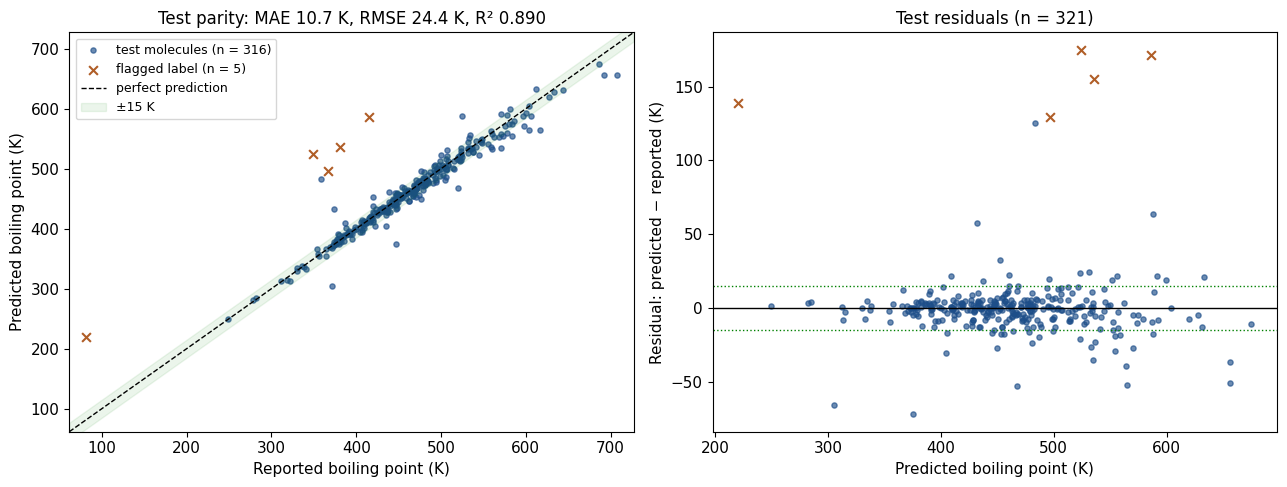

Share of test molecules within ±15 K: 85%; within ±30 K: 94%


In [32]:
p_test = test_preds['Frozen final model']
m_all = metrics(y_test, p_test)
resid = p_test - y_test
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
lims = [min(y_test.min(), p_test.min()) - 20, max(y_test.max(), p_test.max()) + 20]
axes[0].scatter(y_test[~flagged], p_test[~flagged], s=14, alpha=0.65, c='#1D4E89', label=f'test molecules (n = {(~flagged).sum()})')
if flagged.any():
    axes[0].scatter(y_test[flagged], p_test[flagged], s=40, marker='x', c='#B05E27', label=f'flagged label (n = {flagged.sum()})')
axes[0].plot(lims, lims, 'k--', lw=1, label='perfect prediction')
axes[0].fill_between(lims, np.array(lims) - 15, np.array(lims) + 15, color='green', alpha=0.08, label='±15 K')
axes[0].set(xlim=lims, ylim=lims, xlabel='Reported boiling point (K)', ylabel='Predicted boiling point (K)',
            title=f'Test parity: MAE {m_all["MAE_K"]:.1f} K, RMSE {m_all["RMSE_K"]:.1f} K, R² {m_all["R2"]:.3f}')
axes[0].legend(loc='upper left')
axes[1].scatter(p_test[~flagged], resid[~flagged], s=14, alpha=0.65, c='#1D4E89')
if flagged.any():
    axes[1].scatter(p_test[flagged], resid[flagged], s=40, marker='x', c='#B05E27')
axes[1].axhline(0, color='k', lw=1)
for s in (-15, 15):
    axes[1].axhline(s, color='green', ls=':', lw=1)
axes[1].set(xlabel='Predicted boiling point (K)', ylabel='Residual: predicted − reported (K)',
            title=f'Test residuals (n = {len(y_test)})')
fig.tight_layout()
save_fig(fig, 'step10_test_parity_and_residuals.png')
plt.show()
print(f'Share of test molecules within ±15 K: {100 * np.mean(np.abs(resid) <= 15):.0f}%; within ±30 K: {100 * np.mean(np.abs(resid) <= 30):.0f}%')

### Reload the pipeline and predict new molecules

Code Summary: Reloads the saved pipeline from disk in a fresh object, confirms it reproduces the test predictions, and defines an editable prediction function that also reports training similarity and whether the molecule was in the dataset.

In [33]:
reloaded = joblib.load(MODEL_PATH)
assert np.allclose(reloaded.predict(test_df['canonical_smiles']), p_test)
print('Reloaded pipeline reproduces the test predictions exactly. (Loading elsewhere needs the feature module folder on sys.path.)')
known_split = data.set_index('inchikey')['split']
TRAIN_ELEMENTS = {a.GetSymbol() for s in train_df.canonical_smiles for a in Chem.MolFromSmiles(s).GetAtoms()}

def predict_boiling_point(smiles, pipeline=reloaded):
    """Predict normal boiling point (K) from one SMILES string, with applicability-domain notes."""
    mol = bpf.parse_smiles(smiles)
    can = Chem.MolToSmiles(mol)
    sim = float(max_train_similarity([can])[0])
    unseen = sorted({a.GetSymbol() for a in mol.GetAtoms()} - TRAIN_ELEMENTS)
    return {'smiles': smiles, 'predicted_BP_K': round(float(pipeline.predict([can])[0]), 1),
            'joback_stein_brown_K': round(bpf.physchem_descriptors(mol)['JobackSB'], 1),
            'nearest_train_similarity': round(sim, 2),
            'in_dataset': known_split.get(Chem.MolToInchiKey(mol), 'no'),
            'caution': ('elements outside training: ' + ','.join(unseen)) if unseen else ('low similarity' if sim < 0.4 else '')}

# Edit this dictionary to try your own molecules (handbook BP in K for comparison).
examples = {'water': ('O', 373.15), 'ethanol': ('CCO', 351.4), 'benzene': ('c1ccccc1', 353.2),
            'acetic acid': ('CC(=O)O', 391.1), 'n-octane': ('CCCCCCCC', 398.8), 'phenol': ('Oc1ccccc1', 454.9)}
demo = pd.DataFrame([{'molecule': k, **predict_boiling_point(s), 'handbook_BP_K': ref} for k, (s, ref) in examples.items()])
demo['error_K'] = (demo['predicted_BP_K'] - demo['handbook_BP_K']).round(1)
display(demo)

Reloaded pipeline reproduces the test predictions exactly. (Loading elsewhere needs the feature module folder on sys.path.)


,molecule,smiles,predicted_BP_K,joback_stein_brown_K,nearest_train_similarity,in_dataset,caution,handbook_BP_K,error_K
0,water,O,291.6,293.1,0.14,no,low similarity,373.15,-81.5
1,ethanol,CCO,348.7,343.0,0.40,no,,351.40,-2.7
2,benzene,c1ccccc1,345.9,364.4,1.00,train,,353.20,-7.3
3,acetic acid,CC(=O)O,389.2,396.1,0.56,no,,391.10,-1.9
4,n-octane,CCCCCCCC,397.1,388.2,1.00,no,,398.80,-1.7
5,phenol,Oc1ccccc1,449.8,440.5,0.62,no,,454.90,-5.1


### Record runtime and list the generated files

Code Summary: Reports the total notebook runtime, saves a short run summary, and lists every file written to the output folder.

In [34]:
runtime_s = time.perf_counter() - NOTEBOOK_START
run_summary = {'runtime_seconds': round(runtime_s, 1), 'final_experiment_id': FINAL_ID,
               'test_metrics': {k: {m: float(v) for m, v in row.items()} for k, row in test_results.iterrows()},
               'threshold_MAE_K': 15.0, 'threshold_met': bool(test_results.loc['Frozen final model', 'MAE_K'] <= 15.0)}
(OUT / 'run_summary.json').write_text(json.dumps(run_summary, indent=2))
print(f'Total runtime: {runtime_s / 60:.1f} min')
n_exp = len([p for p in EXP_DIR.iterdir() if p.is_dir()])
for p in sorted(OUT.rglob('*')):
    if p.is_file() and 'experiments' not in p.relative_to(OUT).parts and '__pycache__' not in p.parts:
        print(f'  {rel(p)}  ({p.stat().st_size / 1024:.0f} KB)')
print(f'  {rel(EXP_DIR)}/  ({n_exp} experiment folders + experiment_summary.csv)')

Total runtime: 2.2 min
  01_boiling_point/outputs/one_shot_p1/bp_cleaned_train_validation.csv  (424 KB)
  01_boiling_point/outputs/one_shot_p1/bp_eligible_molecules.csv  (292 KB)
  01_boiling_point/outputs/one_shot_p1/bp_frozen_pipeline.joblib  (3637 KB)
  01_boiling_point/outputs/one_shot_p1/bp_one_shot_features.py  (10 KB)
  01_boiling_point/outputs/one_shot_p1/bp_ridge_reference_pipeline.joblib  (5 KB)
  01_boiling_point/outputs/one_shot_p1/environment_versions.json  (0 KB)
  01_boiling_point/outputs/one_shot_p1/figures/step10_test_parity_and_residuals.png  (173 KB)
  01_boiling_point/outputs/one_shot_p1/figures/step4_train_bp_distribution_and_molecular_weight.png  (178 KB)
  01_boiling_point/outputs/one_shot_p1/figures/step5_feature_set_comparison_validation_mae.png  (76 KB)
  01_boiling_point/outputs/one_shot_p1/figures/step5_physchem_permutation_importance.png  (60 KB)
  01_boiling_point/outputs/one_shot_p1/figures/step7_experiment_comparison_mae.png  (166 KB)
  01_boiling_point/

<h3 style="color:#B05E27;">Verdict</h3>

**Test results (n = 321 molecules, evaluated once with the frozen pipeline):**

| Model | MAE (K) | RMSE (K) | R² |
|---|---|---|---|
| Frozen residual SVR | **10.7** | 24.4 | 0.890 |
| Ridge reference (curated descriptors) | 16.8 | 28.7 | 0.847 |
| Training-median baseline | 55.6 | 73.4 | 0.000 |

85% of test molecules are predicted within ±15 K and 94% within ±30 K.

**Verdict: the Step 1 goal is met.** Test MAE 10.7 K is below the 15 K threshold, 81% lower than the median baseline, and 36% lower than the Ridge reference (the requirement was at least 10%). Test MAE is slightly better than validation MAE (11.9 K); with ~320 molecules per split this is ordinary sampling variation, not a sign of leakage.

**Key findings**
1. A classical physics estimate (Joback + Stein–Brown; 21.9 K validation MAE with nothing fitted) is a strong starting point, and letting ML learn only the *correction* to it was the most valuable idea tried (about 1 K better than learning boiling point from scratch for both SVR and boosted trees).
2. Whole-molecule descriptors beat fingerprints: size, polarizability, polarity and shape matter more for boiling point than exactly which substructures are present.
3. Physics-based label checks exposed real data problems (Celsius values stored as kelvin, apparent reduced-pressure values, conflicting isomer reports). Cleaning clearly helped boosted trees but made no measurable difference to the robust SVR. Averaging SVR with boosted trees did not reliably help.
4. RMSE is more than twice MAE because a few molecules are badly wrong. Five test labels are flagged by the Step 5 rule; excluding them (a secondary view only) gives MAE 8.4 K, RMSE 15.0 K, R² 0.955 (n = 316). That subset is not purely "bad labels": it also removes carbon monoxide, whose 81.6 K label is correct.

**Familiar molecules.** Ethanol (−2.7 K), acetic acid (−1.9 K), n-octane (−1.7 K) and phenol (−5.1 K) are predicted well although none of them is in the dataset. Benzene's −7.3 K error versus the handbook reflects the data rather than the model: its only entry (CAS 1076-43-3) is benzene-d₆, recorded at 345.4 K, and deuterium is invisible in SMILES. **Water is badly under-predicted (292 K vs 373 K):** it has the lowest training similarity (0.14), its group-contribution estimate is equally wrong, and its unusually extensive hydrogen-bond network makes it a well-known outlier for additive methods — exactly the applicability-domain failure that the similarity column warns about.

**Limitations**
- *Applicability domain:* only C, H, N, O, S and Cl occur in the data. Fluorinated, brominated, phosphorus or silicon compounds, salts and very small strongly hydrogen-bonded molecules are extrapolation; the prediction function reports nearest-training similarity and flags unseen elements.
- *Label noise:* the source mixes normal boiling points with apparently reduced-pressure or Celsius values. The physics-based rule caught several, but it also mis-handled real values where Joback is weak (sulfones, cyanogen, CO, tetranitromethane; see the Step 5 reviewer note). This was found when reviewing the completed run, after the test evaluation, so it is documented rather than changed.
- *Stereochemistry:* the SMILES carry no stereo, so cis/trans isomers are indistinguishable; their 5–20 K boiling-point differences are irreducible error for this model.
- *Single split:* one 80/10/10 molecule-disjoint split. Validation differences below ~0.5 K are noise, and the score measures interpolation within this chemical space, not performance on new scaffolds.

**Next steps:** (1) strengthen the group-contribution prior (sulfone/sulfoxide and other missing groups, or a modern method such as Nannoolal's) and re-derive the label rule from it; (2) return the SVR/boosted-tree disagreement from `predict_boiling_point` as an uncertainty signal; (3) estimate confidence intervals with repeated group cross-validation and test a scaffold split; (4) try a graph neural network as a residual learner on the same physics baseline (see `examples/01_BP_Chemprop_GNN.ipynb`); (5) check flagged labels against the pressure annotations in the original NIST records.